# Hyperion · 6DOF trajectory

**Goal:** actual AoA below 4° at global max-Qα, with reduced peak Qα. The default case uses an early
5° lean held to 45 s and a 2° AoA command limit. Vehicle, wind, throttle and hardware limits
are unchanged from the comparison case.

Edit the short input cell, then **Restart Kernel → Run All**. Model details are collapsed.
The lookup data and full input/provenance snapshot are **inside this notebook's metadata**;
there is no visible base64 block and no companion data file. Keep the saved notebook in the
kernel's working folder, or update `NOTEBOOK_FILE` below.

Source snapshot: shared drive synchronized **26 October 2026**. This notebook does not fetch
later edits. Results are preliminary rigid-body screening calculations.

In [1]:
# If needed, install once and restart: %pip install numpy scipy pandas matplotlib ipykernel
from pathlib import Path
import copy, hashlib, io, json, math, time, unittest
import numpy as np
import pandas as pd
from scipy.integrate import solve_ivp
from scipy.spatial.transform import Rotation
from IPython.display import display, Markdown, HTML, Image

NOTEBOOK_FILE = Path('Hyperion_6DOF_RK45_Annotated.ipynb')  # Update if renamed or moved.
snapshot = json.loads(NOTEBOOK_FILE.read_text(encoding='utf-8'))['metadata']['hyperion_snapshot']
INPUTS = copy.deepcopy(snapshot['config'])
AERO_DATA = pd.read_csv(io.StringIO(snapshot['aero_csv'])).to_records(index=False)
baseline_trace = pd.read_csv(io.StringIO(snapshot['baseline_trace_csv']))
BASELINE = snapshot['baseline_summary']
assert hashlib.sha256(snapshot['aero_csv'].encode()).hexdigest() == snapshot['aero_sha256']
print(f'Loaded {len(AERO_DATA):,} aerodynamic rows from this notebook.')

Loaded 7,499 aerodynamic rows from this notebook.


## 1 · Inputs

The commanded AoA limit is **not a clip on measured AoA**; actual attitude follows the rigid-body
dynamics. `set_input` accepts any path in the expandable input catalog, including geometry,
tanks, thrust, actuator limits, atmosphere, and separation settings. Units appear in the keys.

In [2]:
def set_input(path, value):
    if path == 'aero.file':
        raise ValueError('The lookup is embedded; replace AERO_DATA explicitly to use a different table.')
    keys = path.split('.'); node = INPUTS
    for key in keys[:-1]: node = node[int(key)] if isinstance(node, list) else node[key]
    node[int(keys[-1]) if isinstance(node, list) else keys[-1]] = value

# Revised pitch program: early 5° lean, hold, then resume pitch-over.
set_input('guidance.pitch_time_s', [0, 3, 12, 45, 90, 140, 200, 1000])
set_input('guidance.pitch_deg',    [90, 90, 85, 85, 50, 25, 12, 0])
set_input('guidance.aoa_command_limit_deg', 2.0)
set_input('guidance.target_altitude_m', 200_000)
set_input('atmosphere.wind_reference_m_s', 7.62)  # At 10 m; existing power law and taper.
set_input('limits.axial_g', 6.0)
set_input('limits.lateral_g', 2.0)
set_input('limits.control_ratio', 2.0)
set_input('solver.rtol', 2e-7)
set_input('solver.max_step_s', 0.4)
set_input('solver.output_step_s', 0.2)
set_input('solver.verbose', False)
# Detailed edit example: set_input('vehicle.stages.0.gimbal_limit_deg', 5.0)
RUN_REFINEMENT = True

In [3]:
for stage in INPUTS['vehicle']['stages']:
    assert np.isclose(sum(t['loaded_mass_kg'] for t in stage['tanks']), stage['propellant_kg'])
    assert stage['startup_propellant_kg'] + stage['residual_kg'] < stage['propellant_kg']
assert INPUTS['limits']['command_axial_g'] <= INPUTS['limits']['axial_g']
display(pd.DataFrame(INPUTS['vehicle']['stages'])[
    ['name','length_m','dry_mass_kg','propellant_kg','thrust_N','isp_s','gimbal_limit_deg']].round(3))
def input_rows(value, path=''):
    if isinstance(value, dict):
        return [r for k,v in value.items() for r in input_rows(v,f'{path}.{k}'.strip('.'))]
    if isinstance(value, list) and any(isinstance(v,dict) for v in value):
        return [r for i,v in enumerate(value) for r in input_rows(v,f'{path}.{i}')]
    return [(path,value)]
input_catalog = pd.DataFrame(input_rows(INPUTS),columns=['Editable path','Value'])
input_catalog = input_catalog[input_catalog.Value.map(lambda v: isinstance(v,(int,float,bool)) or
    (isinstance(v,list) and all(isinstance(x,(int,float,bool)) for x in v)))]
display(HTML('<details><summary>Show detailed input catalog</summary>'+input_catalog.to_html(index=False)+'</details>'))

,name,length_m,dry_mass_kg,propellant_kg,thrust_N,isp_s,gimbal_limit_deg
0,Stage 1,32.625,28518.455,422704.567,6765000,350,5.0
1,Stage 2,28.638,7898.353,66123.849,890000,451,5.0


Editable path,Value
aero.cp_station_offset_m,0.0
aero.reference_area_m2,22.90221
atmosphere.density_scale,1.0
atmosphere.gust_amplitude_m_s,0.0
atmosphere.gust_period_s,12.0
atmosphere.temperature_offset_K,0.0
atmosphere.wind_cap_height_m,1000.0
atmosphere.wind_exponent,0.2
atmosphere.wind_reference_height_m,10.0
atmosphere.wind_reference_m_s,7.62


## 2 · Model and execution

RK45 integrates ECI position/velocity, quaternion attitude `[x,y,z,w]`, three angular rates,
propellant and gimbal states. Body +x points noseward. CM/inertia use dry cylinders and draining
liquid columns. Stage separation rebases the surviving CM and applies an impulse.

$$\mathbf v_a=\mathbf v-\boldsymbol\Omega\times\mathbf r-\mathbf w,\quad
M=|\mathbf v_a|/a,\quad q=\tfrac12\rho|\mathbf v_a|^2,\quad
\mathbf M_A=(\mathbf r_{CP}-\mathbf r_{CM})\times\mathbf F_A.$$

AoA is **total unsigned air-relative incidence**; qα uses **Pa·deg**. CA/CN/CP interpolate over
Mach 0.01–24.99 and 0–4°. Outside-domain values are endpoint-held and flagged. The lower
standard atmosphere has an approximate upper extension; wind is a deterministic case.
Expand the implementation cell to inspect equations, controller and event logic.

In [4]:
# MODEL IMPLEMENTATION — expand to inspect.
G0 = 9.80665

MU = 3.986004418e14

RE = 6371000.0

OMEGA = np.array([0., 0., 7.292115e-5])

def unit(v):
    return v / max(np.linalg.norm(v), 1e-15)

def matrix(q):
    x,y,z,w = q / np.linalg.norm(q)
    return np.array([[1-2*(y*y+z*z),2*(x*y-z*w),2*(x*z+y*w)],
                     [2*(x*y+z*w),1-2*(x*x+z*z),2*(y*z-x*w)],
                     [2*(x*z-y*w),2*(y*z+x*w),1-2*(x*x+y*y)]])

def quaternion_derivative(q,w):
    return .5*np.r_[q[3]*w + np.cross(q[:3],w), -np.dot(q[:3],w)]

def local_frame(r):
    up = unit(r)
    east = unit(np.cross([0.,0.,1.],up))
    north = np.cross(up,east)
    return east,north,up

class Atmosphere:
    """US Standard Atmosphere 1976 lower layers; explicit upper extension.

    Uses geopotential height, hydrostatic pressure and ideal gas. Above 86 km
    a continuous isothermal exponential tail is a SCREENING approximation.
    Wind is a configurable deterministic profile, not a launch-day forecast.
    """
    def __init__(self,c):
        self.c=c
        self.h=np.array([0,11000,20000,32000,47000,51000,71000,84852.])
        self.lapse=np.array([-.0065,0,.001,.0028,0,-.0028,-.002])
        self.tb=[288.15]; self.pb=[101325.]
        for i,L in enumerate(self.lapse):
            dh=self.h[i+1]-self.h[i]; T=self.tb[-1]
            self.tb.append(T+L*dh)
            self.pb.append(self.pb[-1]*(np.exp(-G0*dh/(287.05287*T)) if L==0 else
                         ((T+L*dh)/T)**(-G0/(287.05287*L))))

    def sample(self,h):
        z=max(0.,h); H=6356766*z/(6356766+z)
        if H <= self.h[-1]:
            k=min(6,max(0,np.searchsorted(self.h,H,side='right')-1))
            L=self.lapse[k]; T0=self.tb[k]; dh=H-self.h[k]
            T=T0+L*dh
            p=self.pb[k]*(np.exp(-G0*dh/(287.05287*T0)) if L==0 else
                         (T/T0)**(-G0/(287.05287*L)))
        else:
            T=self.tb[-1]
            p=self.pb[-1]*np.exp(-G0*(H-self.h[-1])/(287.05287*T))
        T += self.c.get('temperature_offset_K',0.)
        rho=p/(287.05287*T)*self.c.get('density_scale',1.)
        a=np.sqrt(1.4*287.05287*T)
        viscosity=1.716e-5*(T/273.15)**1.5*(273.15+110.4)/(T+110.4)
        return T,p,rho,a,viscosity

    def wind(self,h,t,r):
        c=self.c; east,north,_=local_frame(r)
        sp=c['wind_reference_m_s']*(max(h,0.)/c['wind_reference_height_m'])**c['wind_exponent']
        sp=min(sp,c['wind_reference_m_s']*(c['wind_cap_height_m']/c['wind_reference_height_m'])**c['wind_exponent'])
        # Taper above the user-selected atmosphere region; avoid permanent wind in space.
        sp*=np.clip((c['wind_zero_height_m']-h)/max(1.,c['wind_zero_height_m']-c['wind_taper_height_m']),0,1)
        direction=np.deg2rad(c['wind_toward_deg_east_of_north'])
        gust=c.get('gust_amplitude_m_s',0.)*np.sin(2*np.pi*t/c.get('gust_period_s',12.))
        return (sp+gust)*np.cos(direction)*north+(sp+gust)*np.sin(direction)*east

class AeroTable:
    def __init__(self,path,c):
        self.c=c
        a=path  # Structured rows from the embedded table.
        self.alpha=np.unique(a['alpha_deg'])
        self.cols={}
        self.mins=[]; self.maxs=[]
        for angle in self.alpha:
            rows=a[a['alpha_deg']==angle]
            rows=np.sort(rows,order='mach')
            self.cols[angle]=rows
            self.mins.append(rows['mach'].min()); self.maxs.append(rows['mach'].max())
        self.mlo=max(self.mins); self.mhi=min(self.maxs)

    def sample(self,mach,alpha,powered):
        deg=abs(np.rad2deg(alpha)); off=(mach<self.mlo or mach>self.mhi or deg>self.alpha[-1])
        # Endpoint holding is always flagged in output; never claimed as interpolation.
        mm=np.clip(mach,self.mlo,self.mhi); aa=np.clip(deg,self.alpha[0],self.alpha[-1])
        out=[]
        for col in ['ca_on' if powered else 'ca_off','cn','cp_from_nose_m']:
            vals=[np.interp(mm,self.cols[x]['mach'],self.cols[x][col]) for x in self.alpha]
            out.append(float(np.interp(aa,self.alpha,vals)))
        # CN must vanish at zero AoA for the symmetric rigid-body extension.
        if deg<1e-10: out[1]=0.
        return *out,off

class Vehicle:
    def __init__(self,c):
        self.c=c
        self.s=c['stages']
        self.offset=[0.,self.s[0]['length_m']]

    def properties(self,props,attached,fairing):
        components=[]; rad=self.c['diameter_m']/2
        for i,s in enumerate(self.s):
            if i==0 and not attached: continue
            off=self.offset[i]
            dryL=s['length_m']-(self.c['fairing_length_m'] if i==1 else 0.)
            components.append((s['dry_mass_kg'],off+.5*dryL,dryL,rad))
            frac=np.clip(props[i]/s['propellant_kg'],0.,1.)
            for tank in s['tanks']:
                # Equivalent constant-area liquid column drains downward. Slosh omitted.
                liquidL=tank['height_m']*frac
                components.append((tank['loaded_mass_kg']*frac,off+tank['bottom_m']+.5*liquidL,liquidL,rad))
        base=self.offset[1]+self.s[1]['length_m']-self.c['fairing_length_m']
        components.append((self.c['payload_kg'],base+self.c['payload_cg_above_fairing_base_m'],self.c['payload_length_m'],self.c['payload_radius_m']))
        if fairing:
            components.append((self.c['fairing_kg'],base+self.c['fairing_cg_above_base_m'],self.c['fairing_length_m'],rad))
        total=sum(x[0] for x in components)
        cg=sum(m*x for m,x,L,r in components)/total
        # Equivalent uniform solid cylinders + parallel-axis theorem.
        ix=sum(.5*m*r*r for m,x,L,r in components)
        it=sum(m*(3*r*r+L*L)/12+m*(x-cg)**2 for m,x,L,r in components)
        return total,cg,np.array([ix,it,it])

class Simulation:
    def __init__(self,c):
        self.c=c; self.atm=Atmosphere(c['atmosphere'])
        if c['solver'].get('method','RK45')!='RK45': raise ValueError('This simulator requires method=RK45.')
        if c['solver']['max_time_s']<=0: raise ValueError('max_time_s must be positive.')
        for st in c['vehicle']['stages']:
            if not 0<=st['residual_kg']<st['propellant_kg']: raise ValueError('Propellant must exceed residual inventory.')
            if not 0<st['min_throttle']<=1: raise ValueError('Minimum throttle must be in (0,1].')
        self.vehicle=Vehicle(c['vehicle']); self.table=AeroTable(AERO_DATA,c['aero'])
        self.events=[]; self.rows=[]; self.phase=1; self.attached=True; self.fairing=True
        self.cutoff=False; self.ignition_time=0.

    def initial(self):
        lat,lon=np.deg2rad([self.c['launch']['latitude_deg'],self.c['launch']['longitude_deg']])
        props=[s['propellant_kg'] for s in self.c['vehicle']['stages']]
        props[0]-=self.c['vehicle']['stages'][0]['startup_propellant_kg']
        initial_cg=self.vehicle.properties(props,True,True)[1]
        r=(RE+self.c['launch']['altitude_m']+initial_cg)*np.array([np.cos(lat)*np.cos(lon),np.cos(lat)*np.sin(lon),np.sin(lat)])
        e,n,u=local_frame(r)
        q=Rotation.from_matrix(np.column_stack([u,e,n])).as_quat()
        # Start at release with launch vehicle co-rotating with the Earth.
        return np.r_[r,np.cross(OMEGA,r),q,OMEGA@matrix(q),props,0.,0.,0.,0.,0.,0.,0.]

    def guidance(self,t,r,vrel,v,h,qbar):
        c=self.c['guidance']; e,n,u=local_frame(r)
        az=np.deg2rad(self.c['launch']['azimuth_deg']); horizontal=np.sin(az)*e+np.cos(az)*n
        pitch=np.deg2rad(np.interp(t,c['pitch_time_s'],c['pitch_deg']))
        if self.phase==2:
            # Altitude hold with radial-velocity damping while building orbital speed.
            vr=np.dot(v,u); vt=np.linalg.norm(v-vr*u)
            desired_ar=np.clip(c['altitude_gain_s2']*(c['target_altitude_m']-h)-c['vertical_damping_s']*vr,-12.,12.)
            p=self.vehicle.properties(self._props,self.attached,self.fairing)[0]
            thrust=self.c['vehicle']['stages'][1]['thrust_N']
            sinp=np.clip((MU/np.linalg.norm(r)**2-vt*vt/np.linalg.norm(r)+desired_ar)/(thrust/p),-.7,.95)
            pitch=np.arcsin(sinp)
        target=np.cos(pitch)*horizontal+np.sin(pitch)*u
        if t>c.get('aoa_limit_start_s',25.) and qbar>1. and np.linalg.norm(vrel)>100 and np.dot(vrel,horizontal)>0:
            vh=unit(vrel); angle=np.arccos(np.clip(np.dot(target,vh),-1,1))
            # Continuous relaxation as atmosphere thins; avoids a command step at max-Q exit.
            limit=np.deg2rad(min(60.,c['aoa_command_limit_deg']*np.sqrt(max(1.,c['aoa_limit_min_q_Pa']/qbar))))
            if angle>limit:
                tangent=unit(target-vh*np.dot(target,vh))
                target=np.cos(limit)*vh+np.sin(limit)*tangent
        return unit(target)

    def evaluate(self,t,y,record=False):
        c=self.c; r=y[:3]; v=y[3:6]; Q=matrix(y[6:10]); w=y[10:13]
        props=np.maximum(y[13:15],0); self._props=props
        m,cg,I=self.vehicle.properties(props,self.attached,self.fairing)
        h=np.linalg.norm(r)-RE; e,n,u=local_frame(r)
        temp,p,rho,sound,muair=self.atm.sample(h)
        wind=self.atm.wind(h,t,r); vr=v-np.cross(OMEGA,r)-wind
        vb=Q.T@vr; speed=np.linalg.norm(vr); mach=speed/sound
        alpha=np.arctan2(np.linalg.norm(vb[1:]),vb[0]) if speed>1e-5 else 0.
        qbar=.5*rho*speed**2
        powered=self.phase in [1,2] and not self.cutoff
        ca,cn,cpnose,off=self.table.sample(mach,alpha,powered)
        S=c['aero']['reference_area_m2']
        fn=-qbar*S*cn*unit(np.r_[0.,vb[1:]]) if np.linalg.norm(vb[1:])>1e-10 else np.zeros(3)
        Fa=np.r_[-qbar*S*ca,0.,0.]+fn
        # Export geometry is unverified; full-stack applicability assumed, configuration changes flagged.
        nose=sum(s['length_m'] for s in c['vehicle']['stages'])
        if not self.fairing: nose-=c['vehicle']['fairing_length_m']
        cp=nose-cpnose+c['aero'].get('cp_station_offset_m',0.)
        Ma=np.cross(np.array([cp-cg,0.,0.]),Fa)
        idx=0 if self.phase==1 else 1; st=c['vehicle']['stages'][idx]
        engine=self.vehicle.offset[idx]+st['engine_pivot_m']
        arm=cg-engine
        Tfull=st['thrust_N']
        # Optional known nozzle-area correction. Default zero because source lacks area.
        Tfull=max(0.,Tfull+(st['reference_pressure_Pa']-p)*st['exit_area_m2'])
        throttle=0.
        if powered:
            schedule=np.interp(t,c['throttle']['time_s'],c['throttle']['fraction'])
            axial_cap=(m*G0*c['limits']['command_axial_g']-Fa[0])/max(Tfull,1.)
            throttle=np.clip(min(schedule,axial_cap),st['min_throttle'],1.)
        T=Tfull*throttle
        target=self.guidance(t,r,vr,v,h,qbar)
        tb=Q.T@target
        err=np.cross(np.array([1.,0.,0.]),tb)
        ctl=c['control']; wn=ctl['natural_frequency_rad_s']
        wref=Q.T@OMEGA
        angular_command=wn*wn*err-2*ctl['damping_ratio']*wn*(w-wref)
        anorm=np.linalg.norm(angular_command)
        amax=np.deg2rad(ctl.get('angular_acceleration_limit_deg_s2',.3))
        if self.phase==2: amax=np.deg2rad(ctl.get('upper_angular_acceleration_limit_deg_s2',1.5))
        if anorm>amax: angular_command*=amax/anorm
        # Axial roll is held by a separately stated RCS allocation, not engine gimbal.
        mdot=T/(st['isp_s']*G0) if powered else 0.
        dp=np.zeros(2); dp[idx]=-mdot
        Idot=np.zeros(3)
        cgdot=0.; cgddot=0.
        if mdot:
            altered=props.copy(); altered[idx]=max(0.,altered[idx]-1.)
            minus=self.vehicle.properties(altered,self.attached,self.fairing)
            Idot=(minus[2]-I)*mdot
            plusprops=props.copy(); plusprops[idx]+=1.
            plus=self.vehicle.properties(plusprops,self.attached,self.fairing)
            cgp=(plus[1]-minus[1])/2
            cgdot=-cgp*mdot
            # Slow mass-flow variation: exact schedule slope or late-burn g-limit slope.
            n=min(len(c['throttle']['time_s'])-2,max(0,np.searchsorted(c['throttle']['time_s'],t)-1))
            slope=(c['throttle']['fraction'][n+1]-c['throttle']['fraction'][n])/(c['throttle']['time_s'][n+1]-c['throttle']['time_s'][n])
            mdotdot=(Tfull*slope/(st['isp_s']*G0) if schedule<axial_cap and st['min_throttle']<throttle<1 else
                     -mdot*c['limits']['command_axial_g']/st['isp_s'] if axial_cap<schedule and throttle>st['min_throttle'] else 0.)
            cgddot=(plus[1]-2*cg+minus[1])*mdot**2-cgp*mdotdot
        flux=mdot*arm*arm*np.r_[0.,w[1:]]
        Mrequired=I*angular_command+np.cross(w,I*w)+Idot*w+flux-Ma
        limit=np.deg2rad(st['gimbal_limit_deg']); rate=np.deg2rad(st['gimbal_rate_deg_s'])
        # State y[15:17] represents force-direction tilt in body y,z (radians).
        desired=np.array([-Mrequired[2],Mrequired[1]])/max(T*arm,1.) if T>0 and arm>0 else np.zeros(2)
        dn=np.linalg.norm(desired)
        if dn>np.sin(limit): desired*=np.sin(limit)/dn
        desired=np.arcsin(np.clip(desired,-1.,1.))
        gd=(desired-y[15:17])/ctl['actuator_time_constant_s']
        if np.linalg.norm(gd)>rate: gd*=rate/np.linalg.norm(gd)
        gvec=y[15:17].copy(); gn=np.linalg.norm(gvec)
        if gn>limit: gvec*=limit/gn
        Ft=T*np.r_[np.sqrt(max(0.,1.-np.sum(np.sin(gvec)**2))),np.sin(gvec)]
        Mt=np.cross(np.array([-arm,0.,0.]),Ft)
        rcscap=ctl['rcs_moment_Nm'] if not powered else ctl['roll_rcs_moment_Nm']
        Mr=np.zeros(3)
        if not powered:
            mrnorm=np.linalg.norm(Mrequired)
            Mr=Mrequired*min(1.,rcscap/max(mrnorm,1e-12))
        else: Mr[0]=np.clip(Mrequired[0],-rcscap,rcscap)
        wdot=(Ma+Mt+Mr-np.cross(w,I*w)-Idot*w-flux)/I
        gravity=-MU*r/np.linalg.norm(r)**3
        acceleration=Q@(Fa+Ft)/m+gravity
        point=np.array([c['vehicle']['payload_station_m']-cg,0.,0.])
        proper=(Fa+Ft)/m+np.cross(wdot,point)+np.cross(w,np.cross(w,point))
        proper+=2*np.cross(w,np.array([-cgdot,0.,0.]))+np.array([-cgddot,0.,0.])
        vh=unit(v)
        steering=T/m*(1.-np.clip(np.dot(Q@unit(Ft),vh),-1,1)) if T else 0.
        gimbal_loss=T/m*(1.-Ft[0]/T) if T else 0.
        drag_loss=-np.dot(Q@Fa,vh)/m
        grav_loss=-np.dot(gravity,vh)
        deriv=np.r_[v,acceleration,quaternion_derivative(y[6:10],w),wdot,dp,gd,
                    T/m,steering,gimbal_loss,drag_loss,grav_loss]
        if not record: return deriv
        available=T*max(arm,0.)*np.sin(limit)+(ctl['rcs_moment_Nm'] if not powered else 0.)
        aero_moment=np.linalg.norm(Ma[1:]); demand=np.linalg.norm(Mrequired[1:])
        relative=v-np.cross(OMEGA,r)
        def elevation(a): return np.rad2deg(np.arctan2(np.dot(a,u),np.linalg.norm(a-np.dot(a,u)*u)))
        inertial_speed=np.linalg.norm(v); radial=np.dot(v,u)
        hv=np.cross(r,v); ecc=np.linalg.norm(np.cross(v,hv)/MU-unit(r))
        energy=.5*inertial_speed**2-MU/np.linalg.norm(r)
        sma=-MU/(2*energy) if energy<0 else np.inf
        out=dict(t_s=t,phase=self.phase,altitude_m=h,mass_kg=m,cg_from_base_m=cg,
                 Ixx_kg_m2=I[0],Iyy_kg_m2=I[1],Izz_kg_m2=I[2],prop1_kg=props[0],prop2_kg=props[1],
                 cg_rate_m_s=cgdot,cg_acceleration_m_s2=cgddot,
                 airspeed_m_s=speed,inertial_speed_m_s=inertial_speed,vertical_speed_m_s=radial,
                 mach=mach,temperature_K=temp,pressure_Pa=p,density_kg_m3=rho,wind_m_s=np.linalg.norm(wind),
                 reynolds_length=rho*speed*(sum(s['length_m'] for s in c['vehicle']['stages'])-(0. if self.attached else c['vehicle']['stages'][0]['length_m'])-(0. if self.fairing else c['vehicle']['fairing_length_m']))/muair,
                 q_Pa=qbar,alpha_deg=np.rad2deg(alpha),qalpha_Pa_deg=qbar*np.rad2deg(alpha),
                 pitch_deg=elevation(Q[:,0]),heading_deg=np.rad2deg(np.arctan2(np.dot(Q[:,0],e),np.dot(Q[:,0],n)))%360,
                 flight_path_deg=elevation(relative),inertial_flight_path_deg=elevation(v),command_pitch_deg=elevation(target),
                 throttle=throttle,thrust_N=T,gimbal_y_deg=np.rad2deg(gvec[0]),gimbal_z_deg=np.rad2deg(gvec[1]),
                 gimbal_total_deg=np.rad2deg(np.linalg.norm(gvec)),gimbal_rate_deg_s=np.rad2deg(np.linalg.norm(gd)),
                 axial_g=proper[0]/G0,lateral_g=np.linalg.norm(proper[1:])/G0,cm_proper_g=np.linalg.norm(Fa+Ft)/m/G0,
                 aero_moment_Nm=aero_moment,available_moment_Nm=available,required_moment_Nm=demand,
                 actual_control_moment_Nm=np.linalg.norm((Mt+Mr)[1:]),moment_margin_Nm=available-aero_moment,
                 ratio2_margin_Nm=available-c['limits']['control_ratio']*aero_moment,
                 normal_force_N=np.linalg.norm(fn),axial_aero_force_N=-Fa[0],cp_from_base_m=cp,
                 aero_out_of_domain=int(off),aero_configuration_proxy=int(not self.attached or not self.fairing),
                 ideal_dv_m_s=y[17],steering_loss_m_s=y[18],gimbal_loss_m_s=y[19],drag_loss_m_s=y[20],gravity_loss_m_s=y[21],
                 osculating_perigee_m=sma*(1-ecc)-RE,osculating_apogee_m=sma*(1+ecc)-RE,
                 quaternion_norm=np.linalg.norm(y[6:10]))
        for i,k in enumerate(['x','y','z']): out[f'eci_{k}_m']=r[i]; out[f'eci_v{k}_m_s']=v[i]; out[f'body_rate_{k}_deg_s']=np.rad2deg(w[i])
        for i,k in enumerate(['x','y','z','w']): out[f'quaternion_{k}']=y[6+i]
        return out

    def integrate(self,y,t0,t1,events=None):
        c=self.c['solver']
        if c.get('verbose',False): print(f'Integrating phase {self.phase}: t={t0:.2f} s',flush=True)
        atol=np.r_[np.full(3,c['position_atol_m']),np.full(3,c['velocity_atol_m_s']),
                   np.full(4,1e-9),np.full(3,1e-9),np.full(2,1e-4),np.full(2,1e-9),np.full(5,1e-5)]
        sol=solve_ivp(self.evaluate,(t0,t1),y,method='RK45',rtol=c['rtol'],atol=atol,
                      max_step=c['max_step_s'],dense_output=True,events=events)
        if not sol.success: raise RuntimeError(sol.message)
        if c.get('verbose',False): print(f'  reached {sol.t[-1]:.2f} s, {sol.nfev} RHS evaluations',flush=True)
        ts=np.arange(t0,sol.t[-1],c['output_step_s'])
        ts=np.unique(np.r_[ts,sol.t[-1]])
        self.rows.extend(self.evaluate(float(t),sol.sol(t),True) for t in ts)
        return sol.y[:,-1],float(sol.t[-1]),sol

    def run(self):
        y=self.initial(); t=0.; c=self.c
        def burnout1(t,y): return y[13]-c['vehicle']['stages'][0]['residual_kg']
        burnout1.terminal=True; burnout1.direction=-1
        def ground(t,y): return np.linalg.norm(y[:3])-RE+1.
        ground.terminal=True; ground.direction=-1
        self.events.append({'event':'liftoff','t_s':0.})
        y,t,sol=self.integrate(y,t,c['solver']['max_time_s'],[burnout1,ground])
        if not len(sol.t_events[0]):
            self.events.append({'event':'terminated_before_stage1_burnout','t_s':t}); return self.rows,self.events
        self.phase=0
        self.events.append({'event':'MECO','t_s':t})
        y,t,coastsol=self.integrate(y,t,min(t+c['separation']['delay_s'],c['solver']['max_time_s']),[ground])
        if len(coastsol.t_events[0]) or t>=c['solver']['max_time_s']:
            self.events.append({'event':'ground_contact' if len(coastsol.t_events[0]) else 'time_limit','t_s':t})
            return self.rows,self.events
        oldm,oldcg,_=self.vehicle.properties(y[13:15],True,True)
        self.attached=False
        newm,newcg,_=self.vehicle.properties(y[13:15],False,True)
        shift=matrix(y[6:10])@np.array([newcg-oldcg,0.,0.])
        y[:3]+=shift; y[3:6]+=np.cross(matrix(y[6:10])@y[10:13],shift)
        dv=c['separation']['upper_delta_v_m_s']; y[3:6]+=matrix(y[6:10])[:,0]*dv
        self.events.append({'event':'stage_separation','t_s':t,'shed_mass_kg':oldm-newm,'cg_shift_m':newcg-oldcg,
                            'upper_delta_v_m_s':dv,'lower_delta_v_m_s':-newm/(oldm-newm)*dv})
        self.phase=2; self.ignition_time=t
        cg_before=self.vehicle.properties(y[13:15],False,self.fairing)[1]
        y[14]-=c['vehicle']['stages'][1]['startup_propellant_kg']
        cg_after=self.vehicle.properties(y[13:15],False,self.fairing)[1]
        shift=matrix(y[6:10])@np.array([cg_after-cg_before,0.,0.])
        y[:3]+=shift; y[3:6]+=np.cross(matrix(y[6:10])@y[10:13],shift)
        self.events.append({'event':'stage2_ignition','t_s':t})
        def burnout2(t,y): return y[14]-c['vehicle']['stages'][1]['residual_kg']
        burnout2.terminal=True; burnout2.direction=-1
        def insertion(t,y):
            r=y[:3]; v=y[3:6]; radial=np.dot(v,unit(r)); vt=np.linalg.norm(v-radial*unit(r))
            return vt-np.sqrt(MU/np.linalg.norm(r))
        insertion.terminal=True; insertion.direction=1
        def fairing(t,y): return np.linalg.norm(y[:3])-RE-c['separation']['fairing_altitude_m']
        fairing.terminal=True; fairing.direction=1
        event='time_limit'
        while t<c['solver']['max_time_s']:
            if self.fairing and np.linalg.norm(y[:3])-RE >= c['separation']['fairing_altitude_m']:
                before=self.vehicle.properties(y[13:15],False,True)
                self.fairing=False
                after=self.vehicle.properties(y[13:15],False,False)
                shift=matrix(y[6:10])@np.array([after[1]-before[1],0.,0.])
                y[:3]+=shift; y[3:6]+=np.cross(matrix(y[6:10])@y[10:13],shift)
                self.events.append({'event':'fairing_jettison','t_s':t,'shed_mass_kg':before[0]-after[0]})
            es=[burnout2,insertion,ground]+([fairing] if self.fairing else [])
            y,t,sol=self.integrate(y,t,c['solver']['max_time_s'],es)
            if len(sol.t_events[0]): event='stage2_propellant_limit'; break
            if len(sol.t_events[1]): event='orbital_speed_cutoff'; break
            if len(sol.t_events[2]): event='ground_contact'; break
            if self.fairing and len(sol.t_events[3]):
                # Move across root by a negligible distance to execute mass jump next loop.
                y[:3]+=unit(y[:3])*1e-6
                continue
            event='time_limit'; break
        self.events.append({'event':event,'t_s':t})
        if event=='orbital_speed_cutoff':
            self.phase=3; self.cutoff=True
            y,t,_=self.integrate(y,t,t+c['guidance']['post_cutoff_coast_s'],[ground])
            self.events.append({'event':'end_coast','t_s':t})
        return self.rows,self.events

def summarize(df,events,c):
    peaks={}
    for key in ['q_Pa','qalpha_Pa_deg','axial_g','lateral_g','normal_force_N','axial_aero_force_N','aero_moment_Nm','required_moment_Nm','thrust_N','gimbal_total_deg']:
        row=df.loc[df[key].abs().idxmax()]
        peaks[key]={k:float(row[k]) for k in ['t_s',key,'altitude_m','mach','alpha_deg','mass_kg','aero_out_of_domain','aero_configuration_proxy']}
    powered=df[df.thrust_N>0]
    loaded=df[df.q_Pa>100]
    active=df[df.aero_moment_Nm>1.]
    coast=df[df.thrust_N==0]
    ratios=active.available_moment_Nm/active.aero_moment_Nm
    powered_ratios=powered[powered.aero_moment_Nm>1.].available_moment_Nm/powered[powered.aero_moment_Nm>1.].aero_moment_Nm
    cutoff=next((x['t_s'] for x in events if x['event']=='orbital_speed_cutoff'),None)
    end=df.iloc[-1] if cutoff is None else df.iloc[np.argmin(np.abs(df.t_s-cutoff))]
    orbit_ok=bool(cutoff is not None and abs(end.altitude_m-c['guidance']['target_altitude_m'])<5000 and
                  abs(end.vertical_speed_m_s)<30 and end.osculating_perigee_m>(c['guidance']['target_altitude_m']-10000))
    stage2=c['vehicle']['stages'][1]
    burnout_mass=stage2['dry_mass_kg']+c['vehicle']['payload_kg']+stage2['residual_kg']
    reserve=stage2['isp_s']*G0*np.log((stage2['dry_mass_kg']+c['vehicle']['payload_kg']+end.prop2_kg)/burnout_mass)
    checks=dict(axial_acceleration_pass=bool(df.axial_g.abs().max()<=c['limits']['axial_g']),
                lateral_acceleration_pass=bool(df.lateral_g.max()<=c['limits']['lateral_g']),
                nominal_moment_inequality_all_samples=bool((df.moment_margin_Nm>=-1e-8).all()),
                nominal_moment_ratio_requirement_all_samples=bool((df.ratio2_margin_Nm>=-1e-8).all()),
                moment_demand_within_capacity_powered=bool((powered.required_moment_Nm<=powered.available_moment_Nm+1e-6).all()),
                parking_orbit_target_screen_pass=orbit_ok,
                validated_control_authority=False)
    # Rigid-body load cases: interface proper acceleration times supported payload.
    cases=[]
    for name,key in [('Max-Q','q_Pa'),('Max-Qalpha','qalpha_Pa_deg'),('Max axial acceleration','axial_g'),
                     ('Max lateral acceleration','lateral_g'),('Max aerodynamic moment','aero_moment_Nm'),('Max TVC demand','required_moment_Nm'),
                     ('Max thrust','thrust_N'),('Max aerodynamic normal force','normal_force_N'),('Max aerodynamic axial force','axial_aero_force_N')]:
        row=df.loc[df[key].abs().idxmax()].to_dict()
        row['case']=name
        row['payload_axial_force_N']=row['axial_g']*G0*c['vehicle']['payload_kg']
        row['payload_lateral_force_N']=row['lateral_g']*G0*c['vehicle']['payload_kg']
        cases.append(row)
    checks['significant_q_table_domain_pass']=bool((loaded.aero_out_of_domain==0).all())
    checks['powered_moment_ratio_requirement_pass']=bool((powered.ratio2_margin_Nm>=-1e-8).all())
    summary=dict(peaks=peaks,checks=checks,events=events,
        duration_s=float(df.t_s.max()),initial_mass_kg=float(df.mass_kg.iloc[0]),
        ideal_remaining_delta_v_m_s=float(reserve),reference_TMI_delta_v_m_s=c.get('mission',{}).get('TMI_delta_v_m_s',3570.5),
        min_moment_ratio_above_1Nm=float(ratios.min()) if len(ratios) else None,
        min_powered_moment_ratio_above_1Nm=float(powered_ratios.min()) if len(powered_ratios) else None,
        worst_ratio2_margin_Nm=float(df.ratio2_margin_Nm.min()),
        coast_peak_aero_moment_Nm=float(coast.aero_moment_Nm.max()) if len(coast) else 0.,
        additional_coast_moment_for_ratio2_Nm=float(np.maximum(0,coast.aero_moment_Nm*c['limits']['control_ratio']-coast.available_moment_Nm).max()) if len(coast) else 0.,
        aero_outside_table_samples=int(df.aero_out_of_domain.sum()),
        aero_outside_table_above_100Pa_samples=int(loaded.aero_out_of_domain.sum()),
        post_separation_aero_proxy_samples=int(df.aero_configuration_proxy.sum()),
        separation_average_acceleration_g=c['separation']['upper_delta_v_m_s']/c['separation']['impulse_duration_s']/G0,
        peak_aero_outside_table_q_Pa=float(df.loc[df.aero_out_of_domain==1,'q_Pa'].max()) if df.aero_out_of_domain.any() else 0.,
        cutoff_state={k:float(end[k]) for k in ['t_s','altitude_m','inertial_speed_m_s','vertical_speed_m_s',
                     'osculating_perigee_m','osculating_apogee_m','prop2_kg','ideal_dv_m_s','steering_loss_m_s',
                     'gimbal_loss_m_s','drag_loss_m_s','gravity_loss_m_s']},
        assumptions=c['assumptions'])
    return summary,pd.DataFrame(cases)

In [5]:
RUN_CONFIG = copy.deepcopy(INPUTS)
started = time.perf_counter()
rows, events = Simulation(RUN_CONFIG).run()
trajectory = pd.DataFrame(rows)
summary, load_cases = summarize(trajectory, events, RUN_CONFIG)
print(f'RK45: {len(trajectory):,} samples in {time.perf_counter()-started:.1f} s.')

RK45: 2,519 samples in 11.4 s.


## 3 · Results

Comparison uses the original frozen guidance case. Peaks are sampled over the **full run**,
with event endpoints retained. Neither actual AoA nor Qα is clipped. Refinement follows below.

In [6]:
peak = summary['peaks']['qalpha_Pa_deg']; old = BASELINE['peaks']['qalpha_Pa_deg']
cs = summary['cutoff_state']; outside = trajectory[trajectory.alpha_deg >= 4]
reduction = 100*(1-peak['qalpha_Pa_deg']/old['qalpha_Pa_deg'])
requested_pass = peak['alpha_deg'] < 4 and reduction > 0
display(Markdown(f"**Requested criterion: {'PASS' if requested_pass else 'FAIL'}.** "
    f"AoA at max-Qα: **{peak['alpha_deg']:.3f}°**. Peak Qα reduction: **{reduction:.1f}%**."))
display(pd.DataFrame([
    ['AoA at global max-Qα (deg)',old['alpha_deg'],peak['alpha_deg']],
    ['Global max-Qα (kPa·deg)',old['qalpha_Pa_deg']/1000,peak['qalpha_Pa_deg']/1000],
    ['Peak time (s)',old['t_s'],peak['t_s']],
    ['Max-Q (kPa)',BASELINE['peaks']['q_Pa']['q_Pa']/1000,summary['peaks']['q_Pa']['q_Pa']/1000],
    ['Steering loss (m/s)',BASELINE['cutoff_state']['steering_loss_m_s'],cs['steering_loss_m_s']],
],columns=['Metric','Original guidance','Active run']).round(3))
display(Markdown(f"Cutoff orbit: **{cs['osculating_perigee_m']/1000:.3f} × {cs['osculating_apogee_m']/1000:.3f} km**. "
    f"Peak payload loads: **{summary['peaks']['axial_g']['axial_g']:.4f} g axial / "
    f"{summary['peaks']['lateral_g']['lateral_g']:.4f} g lateral**. "
    f"Largest Qα at incidence ≥4°: **{outside.qalpha_Pa_deg.max()/1000:.3f} kPa·deg**. "
    "Early wind incidence and engine-off control limitations remain."))
display(pd.DataFrame({'Check':list(summary['checks']),
    'Result':['PASS' if v else 'FAIL / NOT DEMONSTRATED' for v in summary['checks'].values()]}))

**Requested criterion: PASS.** AoA at max-Qα: **2.183°**. Peak Qα reduction: **51.9%**.

,Metric,Original guidance,Active run
0,AoA at global max-Qα (deg),7.865,2.183
1,Global max-Qα (kPa·deg),66.070,31.806
2,Peak time (s),33.800,46.600
3,Max-Q (kPa),17.920,17.886
4,Steering loss (m/s),1416.876,1410.617


Cutoff orbit: **199.527 × 200.992 km**. Peak payload loads: **5.6884 g axial / 0.0182 g lateral**. Largest Qα at incidence ≥4°: **28.989 kPa·deg**. Early wind incidence and engine-off control limitations remain.

,Check,Result
0,axial_acceleration_pass,PASS
1,lateral_acceleration_pass,PASS
2,nominal_moment_inequality_all_samples,FAIL / NOT DEMONSTRATED
3,nominal_moment_ratio_requirement_all_samples,FAIL / NOT DEMONSTRATED
4,moment_demand_within_capacity_powered,PASS
5,parking_orbit_target_screen_pass,PASS
6,validated_control_authority,FAIL / NOT DEMONSTRATED
7,significant_q_table_domain_pass,FAIL / NOT DEMONSTRATED
8,powered_moment_ratio_requirement_pass,PASS


## 4 · Plots

Comparison first; then trajectory, loads, control/CM, attitude/atmosphere, and Mach/velocity.
Dotted lines mark governing load peaks; dashed lines mark flight events. Mach uses air-relative
speed and local sound speed. The gimbal loss diagnostic is **non-additive** to steering loss.

In [7]:
# PLOTTING IMPLEMENTATION — expand to inspect.
def plot_results(df,s,c):
    import matplotlib
    import matplotlib.pyplot as plt
    plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,
                         'grid.alpha':.18,'figure.facecolor':'#f7f9fc','axes.facecolor':'white','lines.linewidth':1.7})
    times=[s['peaks'][k]['t_s'] for k in ['q_Pa','qalpha_Pa_deg','axial_g','lateral_g']]
    colors=['#b76404','#b8226b','#bd2424','#7a48aa']
    labels=['Max-Q','Max-Qα','Max axial g','Max lateral g']
    def marks(ax,allmarks=True):
        for x,col,lab in zip(times,colors,labels):
            if allmarks: ax.axvline(x,color=col,ls=':',lw=1,alpha=.8,label=lab)
        for ev in s['events']:
            if ev['event'] in ['stage_separation','fairing_jettison','orbital_speed_cutoff']:
                ax.axvline(ev['t_s'],color='#546780',ls='--',lw=.8)
        ax.set_xlabel('Time since release (s)')
    def save(fig,name,title):
        fig.suptitle(title,fontsize=16,fontweight='bold',x=.05,ha='left')
        fig.text(.05,.015,'Hyperion • Synced 26 Oct 2026 inputs • Preliminary rigid-body model; actuator capability assumed',fontsize=9,color='#586579')
        if name!='04_orientation_atmosphere.png':
            from matplotlib.lines import Line2D
            fig.legend([Line2D([0],[0],color=co,ls=':') for co in colors],labels,ncol=4,loc='upper center',bbox_to_anchor=(.5,.952),frameon=False)
        fig.tight_layout(rect=[0,.035,1,.915]);buf=io.BytesIO();fig.savefig(buf,format='png',dpi=120);display(Image(data=buf.getvalue()));plt.close(fig)
    t=df.t_s
    fig,ax=plt.subplots(3,2,figsize=(14,11))
    ax[0,0].plot(t,df.altitude_m/1000);ax[0,0].axhline(c['guidance']['target_altitude_m']/1000,color='gray',ls='--');ax[0,0].set_ylabel('Altitude (km)')
    # ECEF ground-track arc from initial position, independent of Earth's rotation.
    theta=7.292115e-5*t.to_numpy();x=df.eci_x_m.to_numpy();y=df.eci_y_m.to_numpy();z=df.eci_z_m.to_numpy()
    re=np.column_stack([np.cos(theta)*x+np.sin(theta)*y,-np.sin(theta)*x+np.cos(theta)*y,z]);re/=np.linalg.norm(re,axis=1)[:,None]
    down=RE*np.arccos(np.clip(re@re[0],-1,1))/1000
    df['ground_range_km']=down
    ax[0,1].plot(down,df.altitude_m/1000);ax[0,1].set(xlabel='Ground arc from launch (km)',ylabel='Altitude (km)')
    for tt,col,lab in zip(times,colors,labels):
        j=np.argmin(abs(t-tt));ax[0,1].scatter(down[j],df.altitude_m.iloc[j]/1000,color=col,s=30,label=lab)
    ax[1,0].plot(t,df.pitch_deg,label='Body elevation');ax[1,0].plot(t,df.command_pitch_deg,ls='--',label='Command');ax[1,0].set_ylabel('Orientation / elevation (deg)');ax[1,0].legend()
    ax[1,1].plot(t,df.flight_path_deg,label='Earth-relative');ax[1,1].plot(t,df.inertial_flight_path_deg,label='Inertial',alpha=.6);ax[1,1].set_ylabel('Flight path angle (deg)');ax[1,1].legend()
    ax[2,0].plot(t,df.alpha_deg);ax[2,0].axhline(4,color='red',ls='--',label='Table AoA boundary');ax[2,0].set_ylabel('Total angle of attack (deg)');ax[2,0].legend()
    ax[2,1].plot(t,df.thrust_N/1e6,label='Thrust');ax[2,1].set_ylabel('Commanded thrust (MN)')
    for axis in ax.flat:
        if axis is not ax[0,1]: marks(axis)
    ax[0,1].legend(fontsize=8)
    save(fig,'01_trajectory.png','Trajectory, attitude, and thrust')
    fig,ax=plt.subplots(3,2,figsize=(14,11))
    ax[0,0].plot(t,df.q_Pa/1000);ax[0,0].set_ylabel('Dynamic pressure (kPa)')
    ax[0,1].plot(t,df.qalpha_Pa_deg/1000);ax[0,1].set_ylabel('q × |α| (kPa·deg)')
    if s['peaks']['qalpha_Pa_deg']['aero_out_of_domain']:
        ax[0,1].text(.43,.80,'Max-Qα is outside the 4° AoA table.\nForce/moment prediction is conditional.',transform=ax[0,1].transAxes,color='#b8226b',fontsize=9)
    ax[1,0].plot(t,df.axial_g,label='Payload axial');ax[1,0].axhline(c['limits']['axial_g'],color='red',ls='--',label=f"{c['limits']['axial_g']:g} g limit");ax[1,0].set_ylabel('Axial proper acceleration (g)');ax[1,0].legend()
    ax[1,1].plot(t,df.lateral_g);ax[1,1].axhline(c['limits']['lateral_g'],color='red',ls='--',label=f"{c['limits']['lateral_g']:g} g limit");ax[1,1].set_ylabel('Payload lateral acceleration (g)');ax[1,1].legend()
    ax[2,0].plot(t,df.normal_force_N/1000,label='Normal');ax[2,0].plot(t,df.axial_aero_force_N/1000,label='Axial');ax[2,0].set_ylabel('Aerodynamic force (kN)');ax[2,0].legend()
    for fk,offset in [('normal_force_N',(15,15)),('axial_aero_force_N',(15,-20))]:
        pk=s['peaks'][fk]
        ax[2,0].scatter(pk['t_s'],pk[fk]/1000,s=25,color='#b8226b')
        ax[2,0].annotate(f"{pk[fk]/1000:.2f} kN @ {pk['t_s']:.1f} s",(pk['t_s'],pk[fk]/1000),xytext=offset,textcoords='offset points',fontsize=8)
    ax[2,1].plot(t,df.aero_moment_Nm/1e6);ax[2,1].set_ylabel('Aerodynamic moment about CM (MN·m)')
    for axis,key,scale,units in [(ax[0,0],'q_Pa',1000,'kPa'),(ax[0,1],'qalpha_Pa_deg',1000,'kPa·deg'),
                               (ax[1,0],'axial_g',1,'g'),(ax[1,1],'lateral_g',1,'g'),(ax[2,1],'aero_moment_Nm',1e6,'MN·m')]:
        peak=s['peaks'][key];axis.scatter(peak['t_s'],peak[key]/scale,s=35,color='#b8226b',zorder=5)
        axis.annotate(f"{peak[key]/scale:.3f} {units} @ {peak['t_s']:.1f} s",(peak['t_s'],peak[key]/scale),xytext=(12,18 if key=='lateral_g' else -22),textcoords='offset points',fontsize=9)
    for axis in ax.flat:marks(axis)
    ax[0,0].legend(loc='upper right',fontsize=8)
    save(fig,'02_load_cases.png','Maximum aerodynamic and payload loads')
    fig,ax=plt.subplots(3,2,figsize=(14,11))
    ax[0,0].plot(t,df.gimbal_y_deg,label='Body y tilt');ax[0,0].plot(t,df.gimbal_z_deg,label='Body z tilt');ax[0,0].plot(t,df.gimbal_total_deg,label='Total',color='black',alpha=.5);ax[0,0].set_ylabel('Gimbal angle (deg)');ax[0,0].legend()
    ax[0,1].plot(t,df.throttle*100);ax[0,1].set_ylabel('Throttle command (%)')
    for name,lab in [('aero_moment_Nm','Aero disturbance'),('available_moment_Nm','Available control'),('required_moment_Nm','Tracking demand'),('actual_control_moment_Nm','Applied control')]:
        ax[1,0].plot(t,df[name]/1e6,label=lab)
    ax[1,0].set_ylabel('Moment magnitude (MN·m)');ax[1,0].legend(fontsize=8)
    ax[1,1].plot(t,df.ratio2_margin_Nm/1e6);ax[1,1].axhline(0,color='red',ls='--');ax[1,1].fill_between(t,df.ratio2_margin_Nm/1e6,0,where=df.ratio2_margin_Nm<0,color='red',alpha=.3);ax[1,1].set_ylabel(f'Available − {c["limits"]["control_ratio"]:g} × aero (MN·m)')
    meco=next((ev['t_s'] for ev in s['events'] if ev['event']=='MECO'),None)
    if meco is not None:
        ins=ax[1,1].inset_axes([.48,.30,.48,.42])
        ins.plot(t,df.ratio2_margin_Nm/1000,color='#b8226b');ins.axhline(0,color='red',ls='--',lw=.8)
        ins.set_xlim(meco-.2,meco+c['separation']['delay_s']+.2)
        deficit=s['additional_coast_moment_for_ratio2_Nm']/1000
        inset_scale=max(1.,deficit)
        ins.set_ylim(-inset_scale*1.25,inset_scale*.35);ins.tick_params(labelsize=7)
        ins.set_title('Engine-off gap (kN·m)',fontsize=8)
        ax[1,1].text(.48,.86,f'Coast requirement shortfall: {deficit:.1f} kN·m',transform=ax[1,1].transAxes,color='#b8226b',fontsize=9)
    ax[2,0].plot(t,df.mass_kg/1000,label='Mass');ax[2,0].set_ylabel('Mass (tonnes)');other=ax[2,0].twinx();other.plot(t,df.cg_from_base_m,color='#b76404');other.set_ylabel('CM from original base (m)',color='#b76404')
    for key,lab in [('steering_loss_m_s','Thrust direction'),('gimbal_loss_m_s','Gimbal diagnostic (non-additive)'),('drag_loss_m_s','Aero work'),('gravity_loss_m_s','Gravity')]:ax[2,1].plot(t,df[key],label=lab)
    ax[2,1].set_ylabel('Integrated velocity losses (m/s)');ax[2,1].legend(fontsize=8)
    for axis in ax.flat:marks(axis)
    ax[0,1].legend(loc='lower left',fontsize=8)
    save(fig,'03_control_and_mass.png','Control authority, gimbal motion, and mass depletion')
    fig,ax=plt.subplots(3,2,figsize=(14,11))
    for k in ['x','y','z','w']:ax[0,0].plot(t,df['quaternion_'+k],label=k)
    ax[0,0].set_ylabel('Body-to-ECI quaternion');ax[0,0].legend(ncol=4)
    for k in ['x','y','z']:ax[0,1].plot(t,df['body_rate_'+k+'_deg_s'],label=k)
    ax[0,1].set_ylabel('Body angular rates (deg/s)');ax[0,1].legend()
    ax[1,0].plot(t,df.temperature_K);ax[1,0].set_ylabel('Temperature (K)')
    ax[1,1].semilogy(t,np.maximum(df.pressure_Pa,1e-12),label='Pressure (Pa)');ax[1,1].semilogy(t,np.maximum(df.density_kg_m3,1e-12),label='Density (kg/m³)');ax[1,1].legend()
    ax[2,0].plot(t,df.wind_m_s);ax[2,0].set_ylabel('Wind speed (m/s)')
    ax[2,1].plot(t,df.Iyy_kg_m2/1e6,label='Pitch/yaw');ax[2,1].plot(t,df.Ixx_kg_m2/1e6,label='Roll');ax[2,1].set_ylabel('Principal inertia (10⁶ kg·m²)');ax[2,1].legend()
    for axis in ax.flat:marks(axis,False)
    save(fig,'04_orientation_atmosphere.png','Full attitude state and atmospheric environment')
    fig,ax=plt.subplots(2,1,figsize=(14,9),sharex=True)
    ax[0].plot(t,df.mach,color='#205e96',label='Air-relative Mach number')
    ax[0].axhline(1,color='#8b98a7',ls='--',lw=.9,label='Mach 1')
    ax[0].set_ylabel('Mach number (air-relative speed / local sound speed)')
    ax[0].legend(loc='upper left',fontsize=9)
    ax[1].plot(t,df.airspeed_m_s/1000,color='#205e96',label='Air-relative speed')
    ax[1].plot(t,df.inertial_speed_m_s/1000,color='#148579',ls='--',label='Earth-centered inertial speed')
    ax[1].set_ylabel('Speed (km/s)')
    ax[1].legend(loc='upper left',fontsize=9)
    for axis in ax:marks(axis)
    for event in s['events']:
        if event['event'] in ['stage_separation','fairing_jettison','orbital_speed_cutoff']:
            event_label={'stage_separation':'Stage separation','fairing_jettison':'Fairing jettison',
                         'orbital_speed_cutoff':'Engine cutoff'}[event['event']]
            ax[0].text(event['t_s']+3,.97,event_label,transform=ax[0].get_xaxis_transform(),
                       rotation=90,ha='left',va='top',fontsize=8,color='#546780')
    save(fig,'05_velocity_mach.png','Velocity and Mach history')

def compare_plot(current):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    baseline = baseline_trace
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    for df, label, color in [(baseline, 'Original guidance', '#8e637d'), (current, 'Selected guidance', '#136d9d')]:
        early = df[df.t_s <= 120]
        axes[0, 0].plot(early.t_s, early.qalpha_Pa_deg/1000, label=label, color=color)
        pk = df.loc[df.qalpha_Pa_deg.idxmax()]
        axes[0, 0].scatter(pk.t_s, pk.qalpha_Pa_deg/1000, color=color, zorder=5)
        axes[0, 0].annotate(f'{pk.qalpha_Pa_deg/1000:.2f} kPa·deg\nα={pk.alpha_deg:.2f}°',
                           (pk.t_s, pk.qalpha_Pa_deg/1000), xytext=(8, 9), textcoords='offset points', color=color, fontsize=9)
        axes[0, 1].plot(early.t_s, early.alpha_deg, label=label, color=color)
        axes[1, 0].plot(early.t_s, early.q_Pa/1000, label=label, color=color)
        axes[1, 1].plot(early.t_s, early.pitch_deg, label=label, color=color)
    axes[0, 0].set_ylabel('q × total incidence (kPa·deg)')
    axes[0, 0].set_ylim(0, max(80., current.qalpha_Pa_deg.max()/1000*1.2))
    axes[0, 1].set_ylabel('Actual total incidence (deg)')
    axes[0, 1].axhline(4, color='#bc3434', ls='--', label='4° table boundary')
    axes[1, 0].set_ylabel('Dynamic pressure (kPa)')
    axes[1, 1].set_ylabel('Nose elevation above local horizontal (deg)')
    for ax in axes.flat:
        ax.set_xlabel('Time since release (s)'); ax.grid(alpha=.2); ax.legend(fontsize=9)
    fig.suptitle('Active trajectory versus frozen original guidance', fontsize=15)
    fig.text(.04, .015, 'Global qα maxima are computed over the full run. Initial wind incidence remains outside the table; preliminary rigid-body model.', fontsize=9)
    fig.tight_layout(rect=[0, .035, 1, .95]); buf=io.BytesIO(); fig.savefig(buf,format='png',dpi=120); display(Image(data=buf.getvalue())); plt.close(fig)

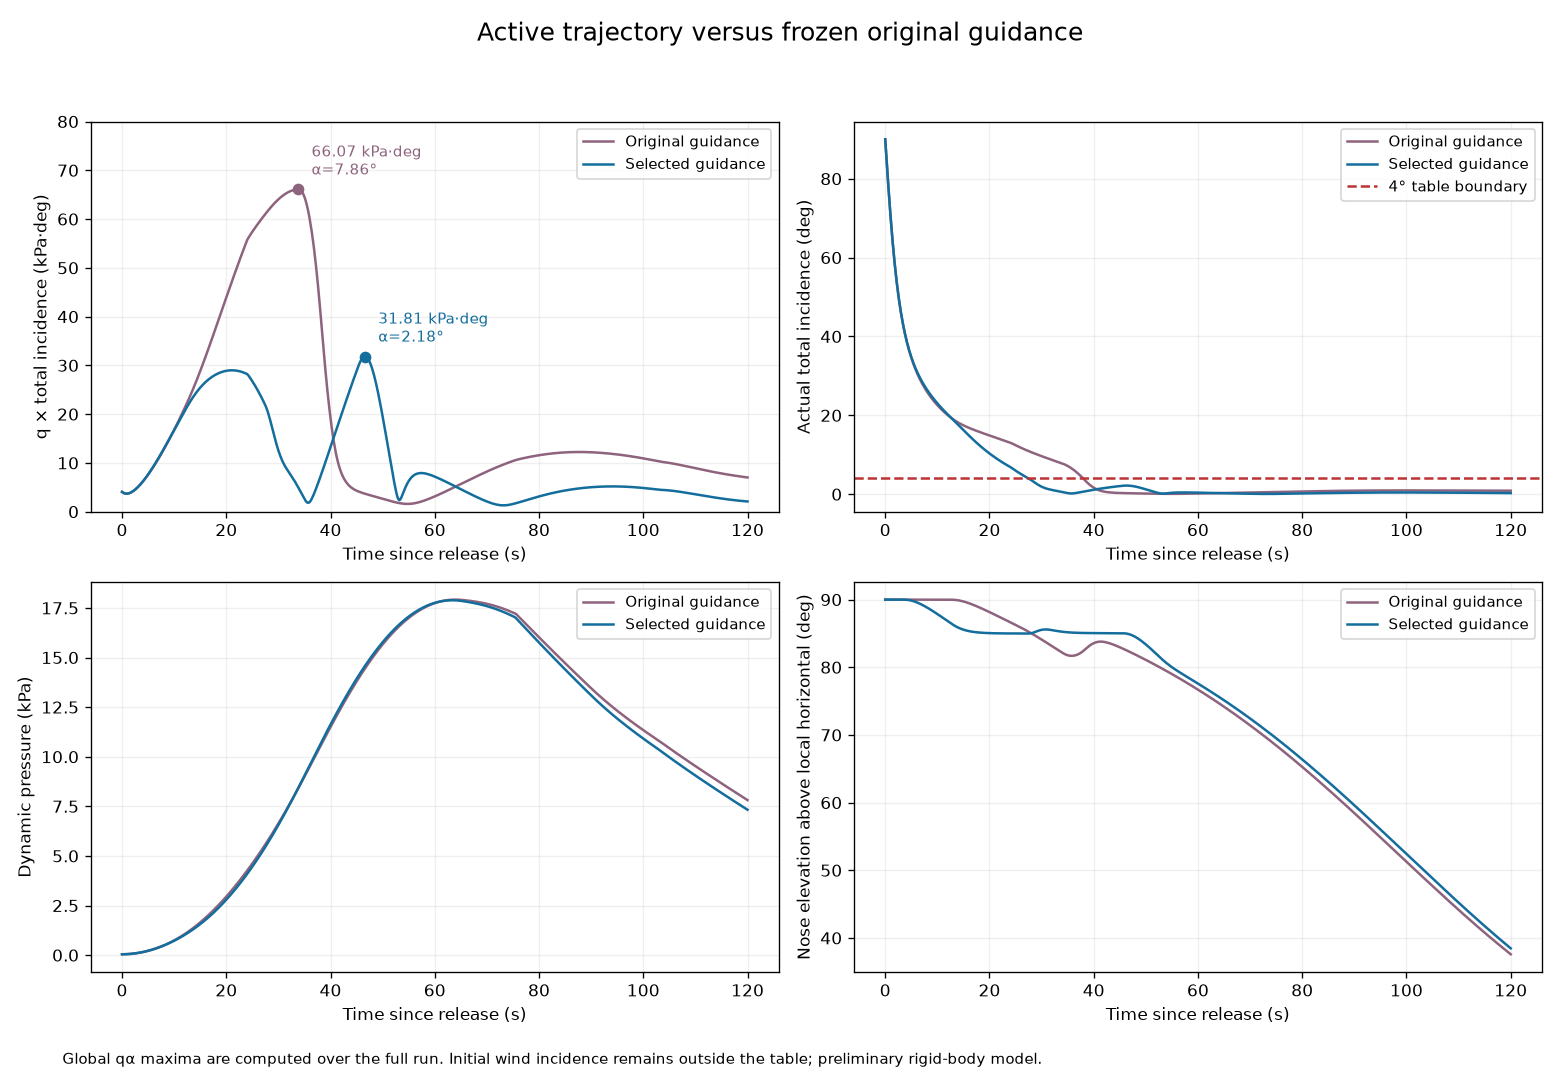

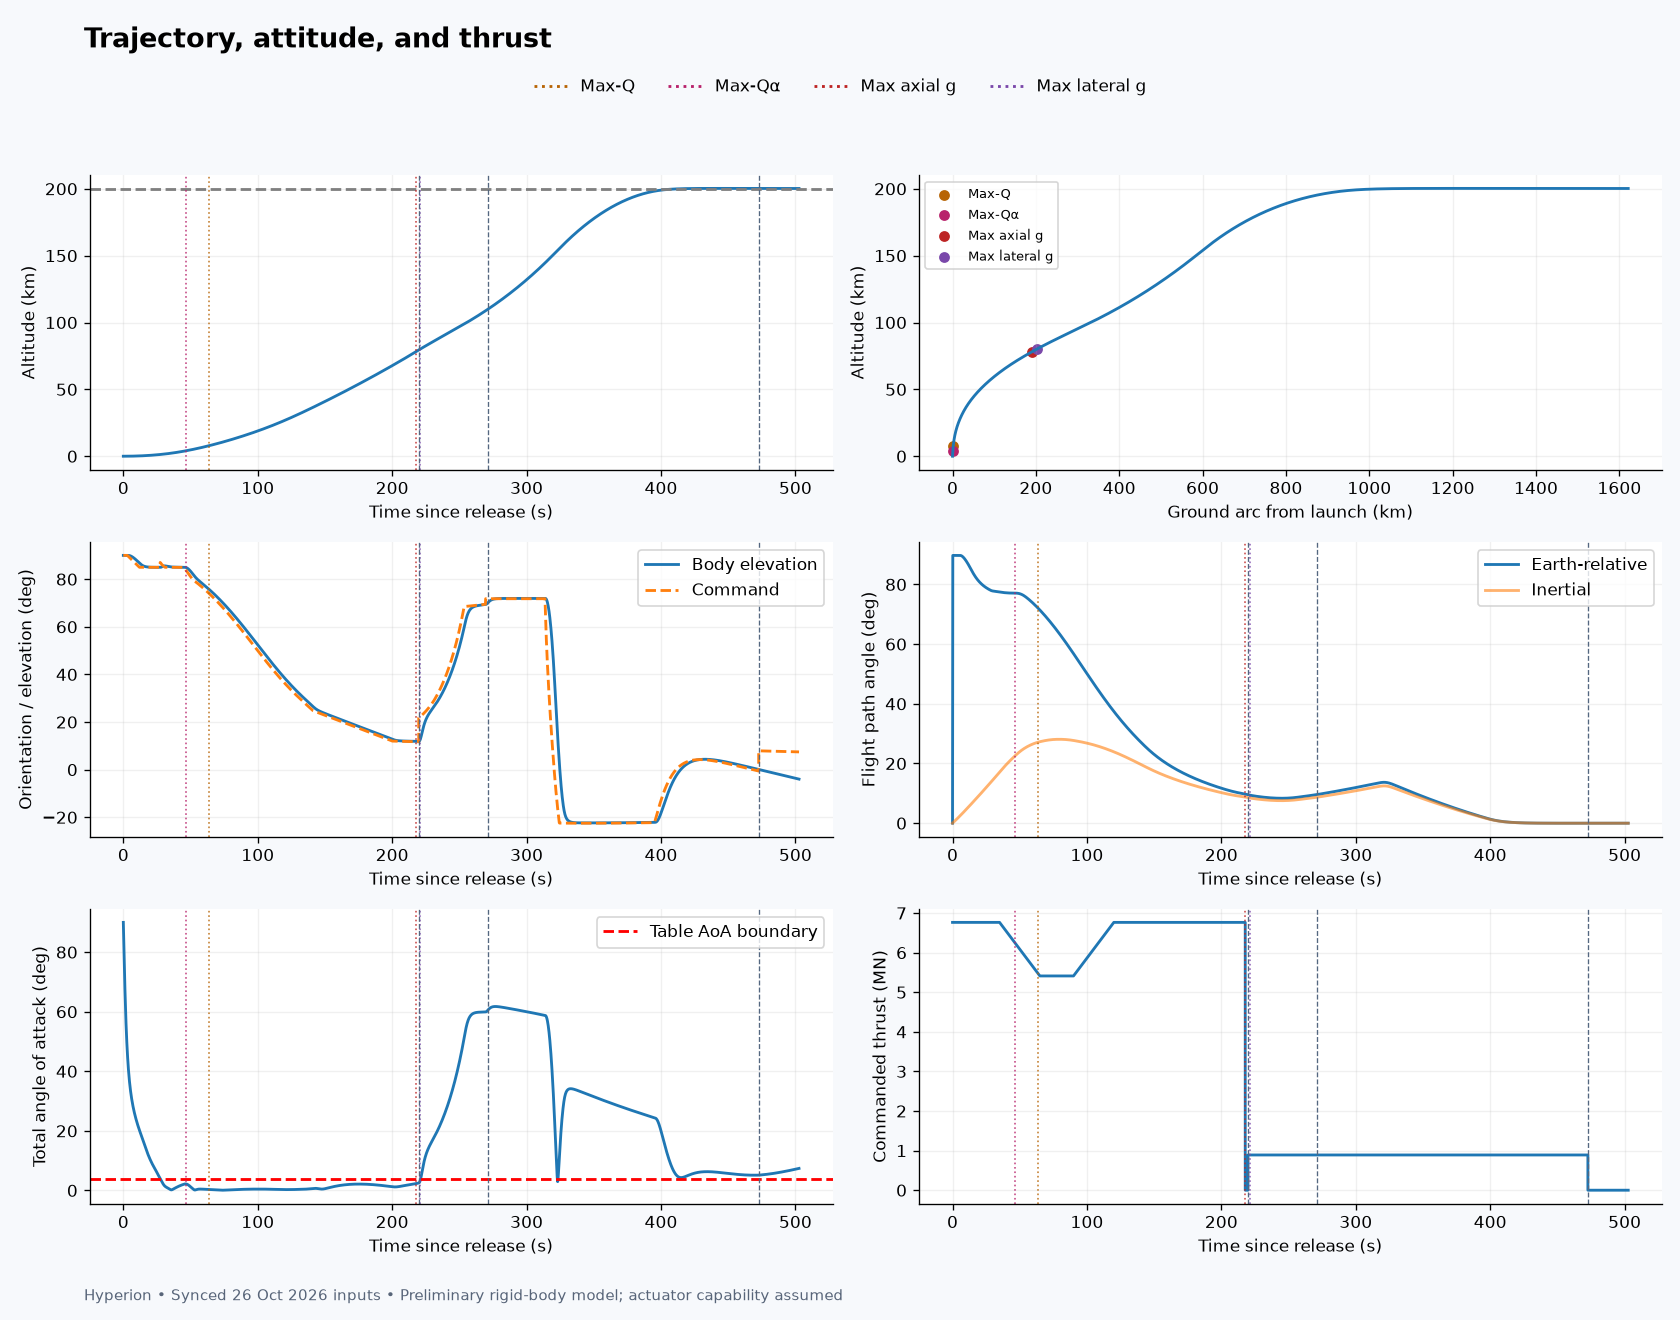

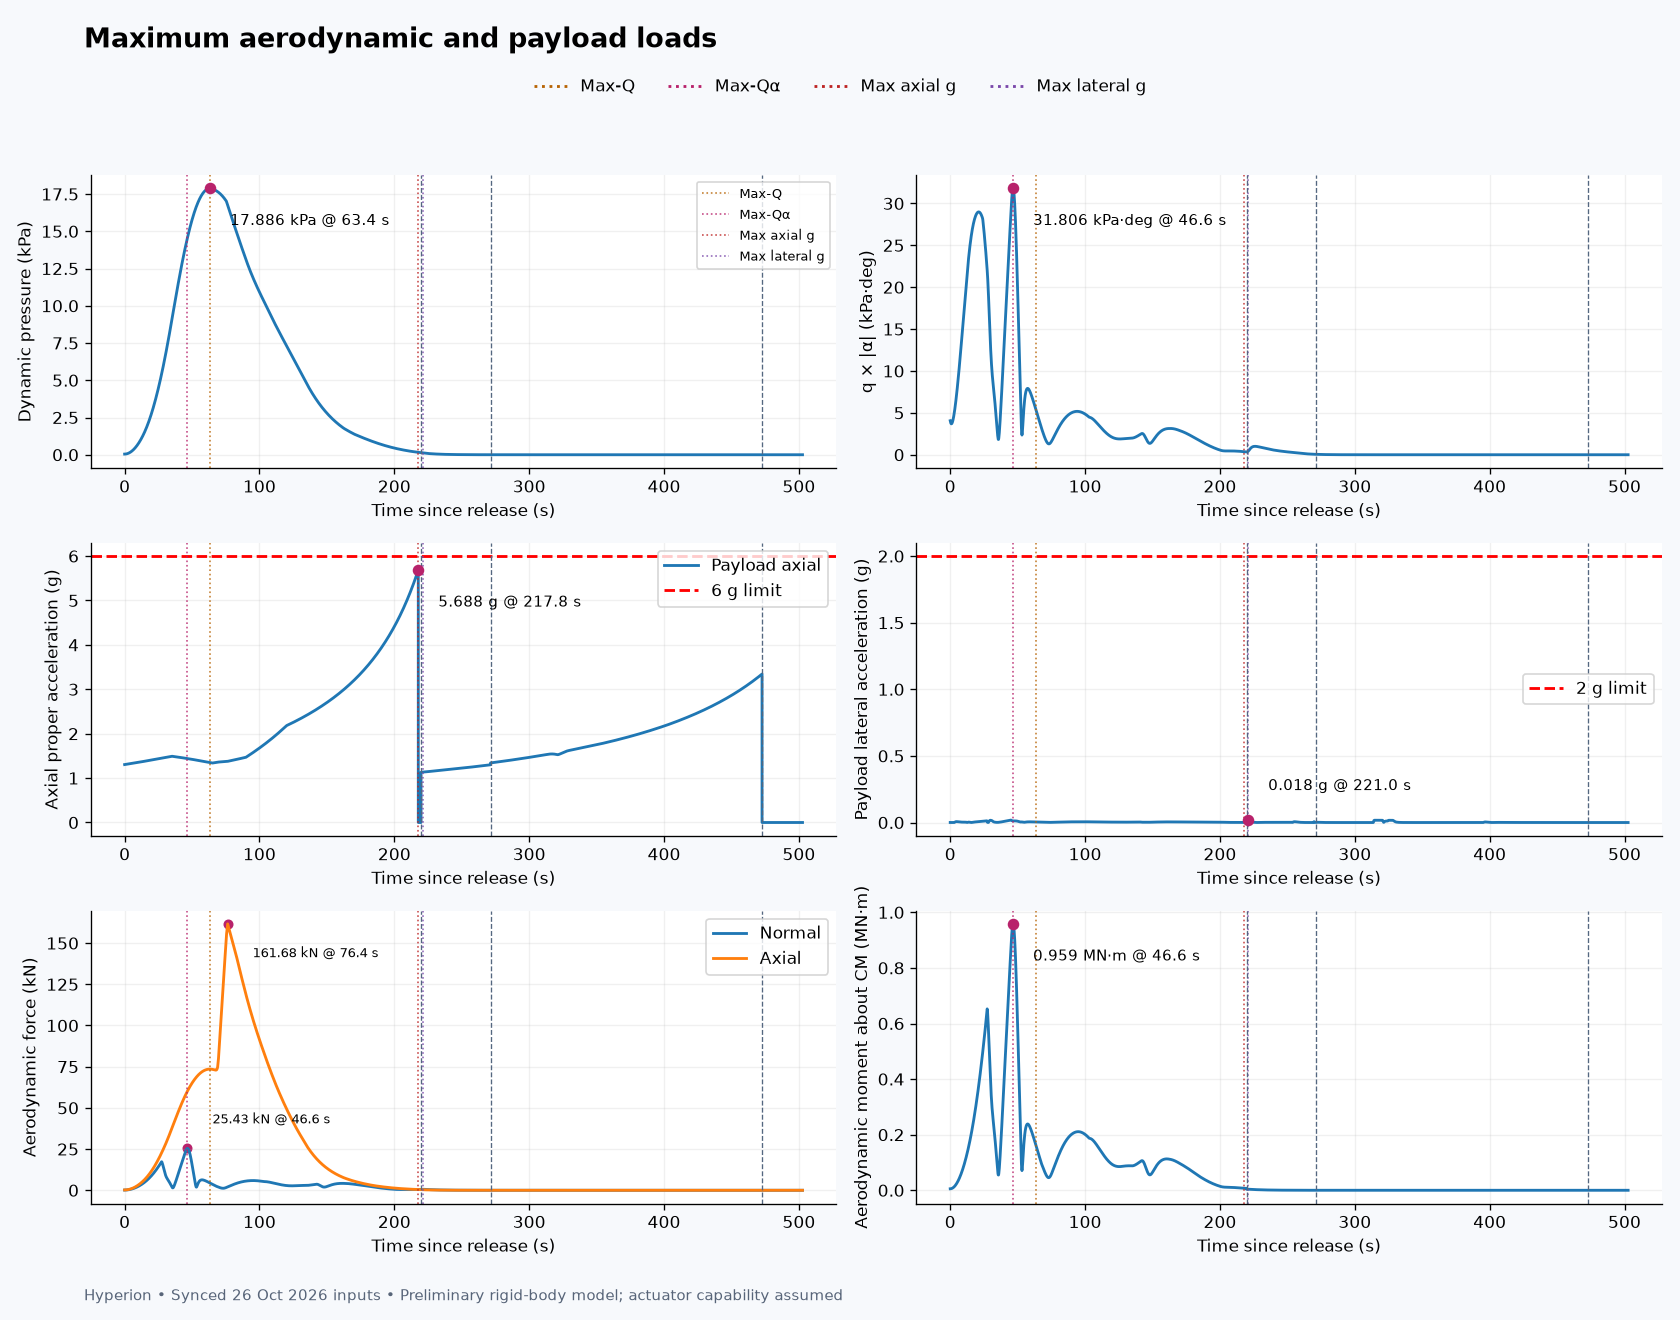

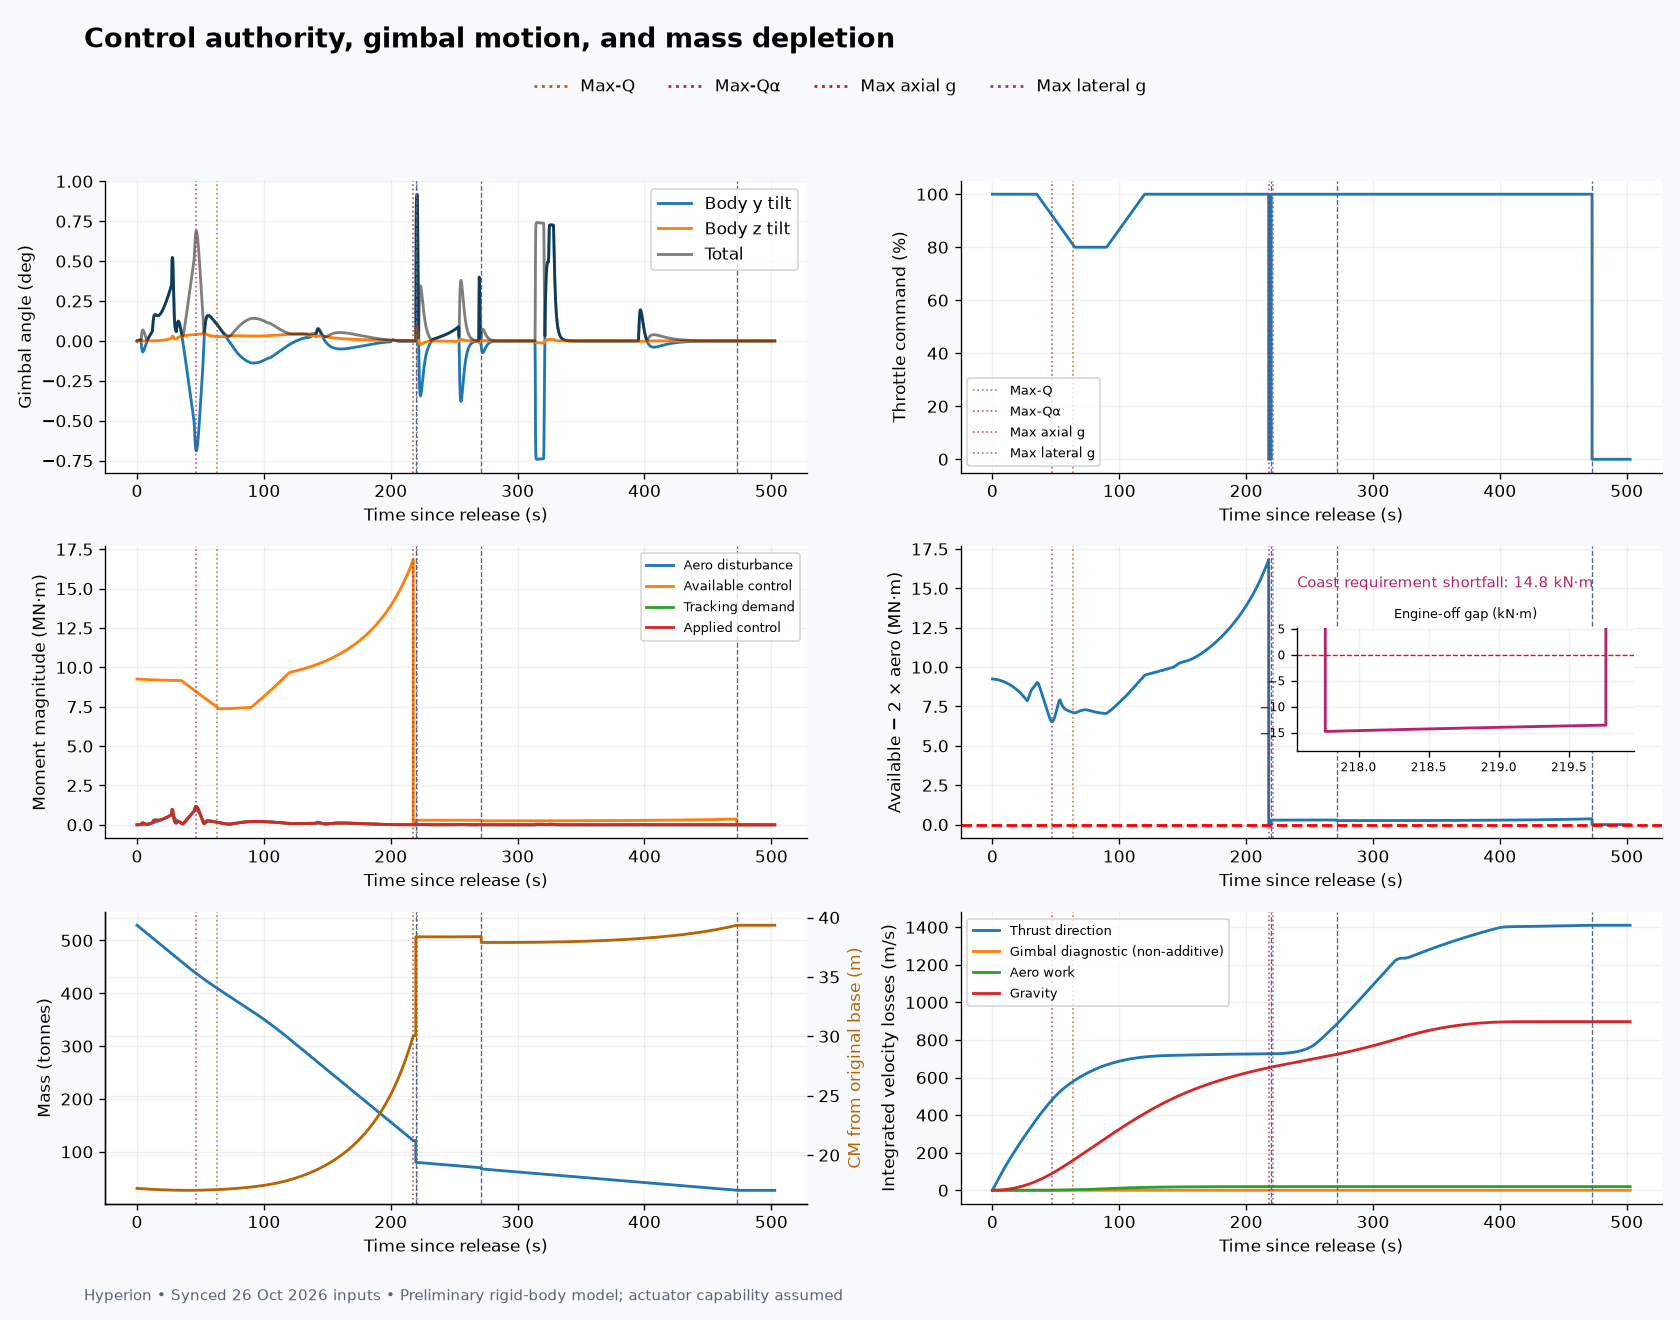

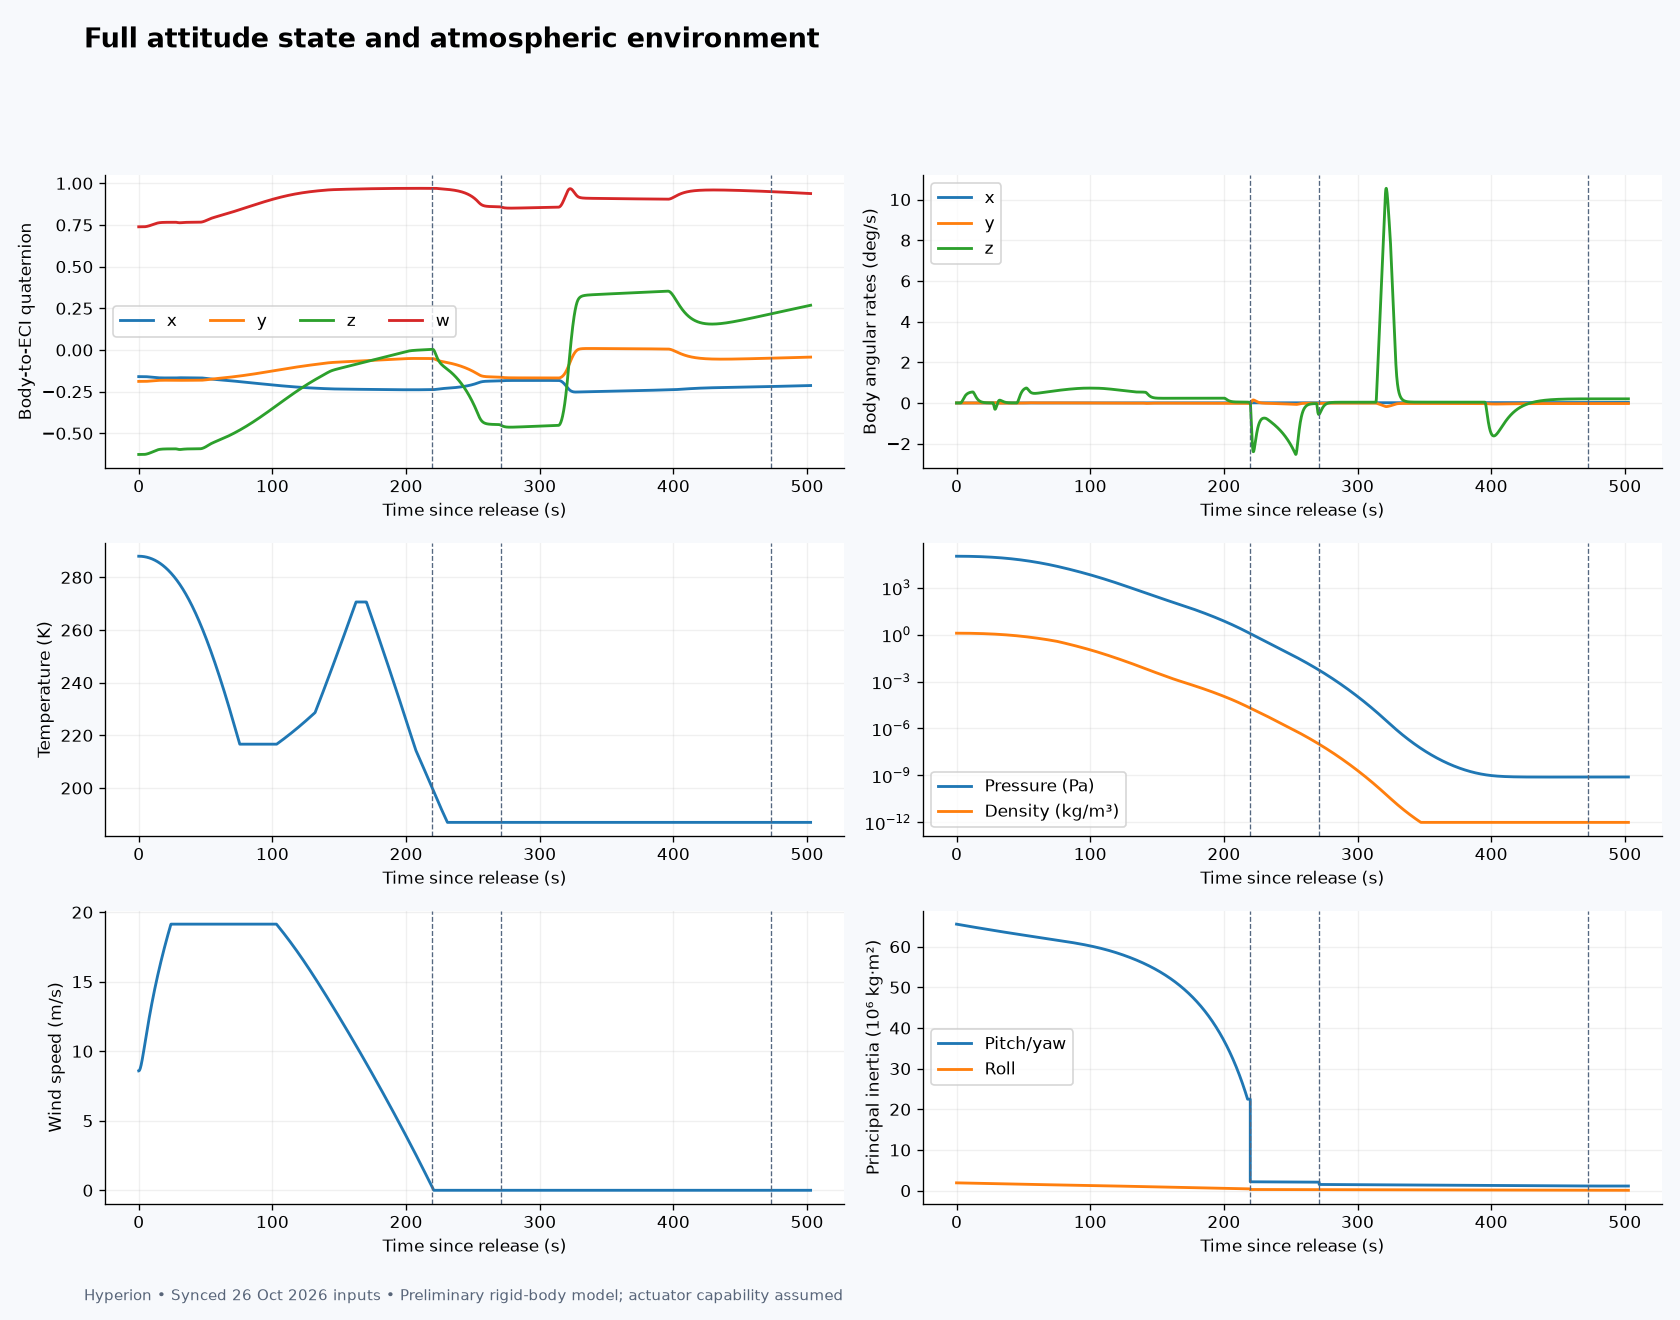

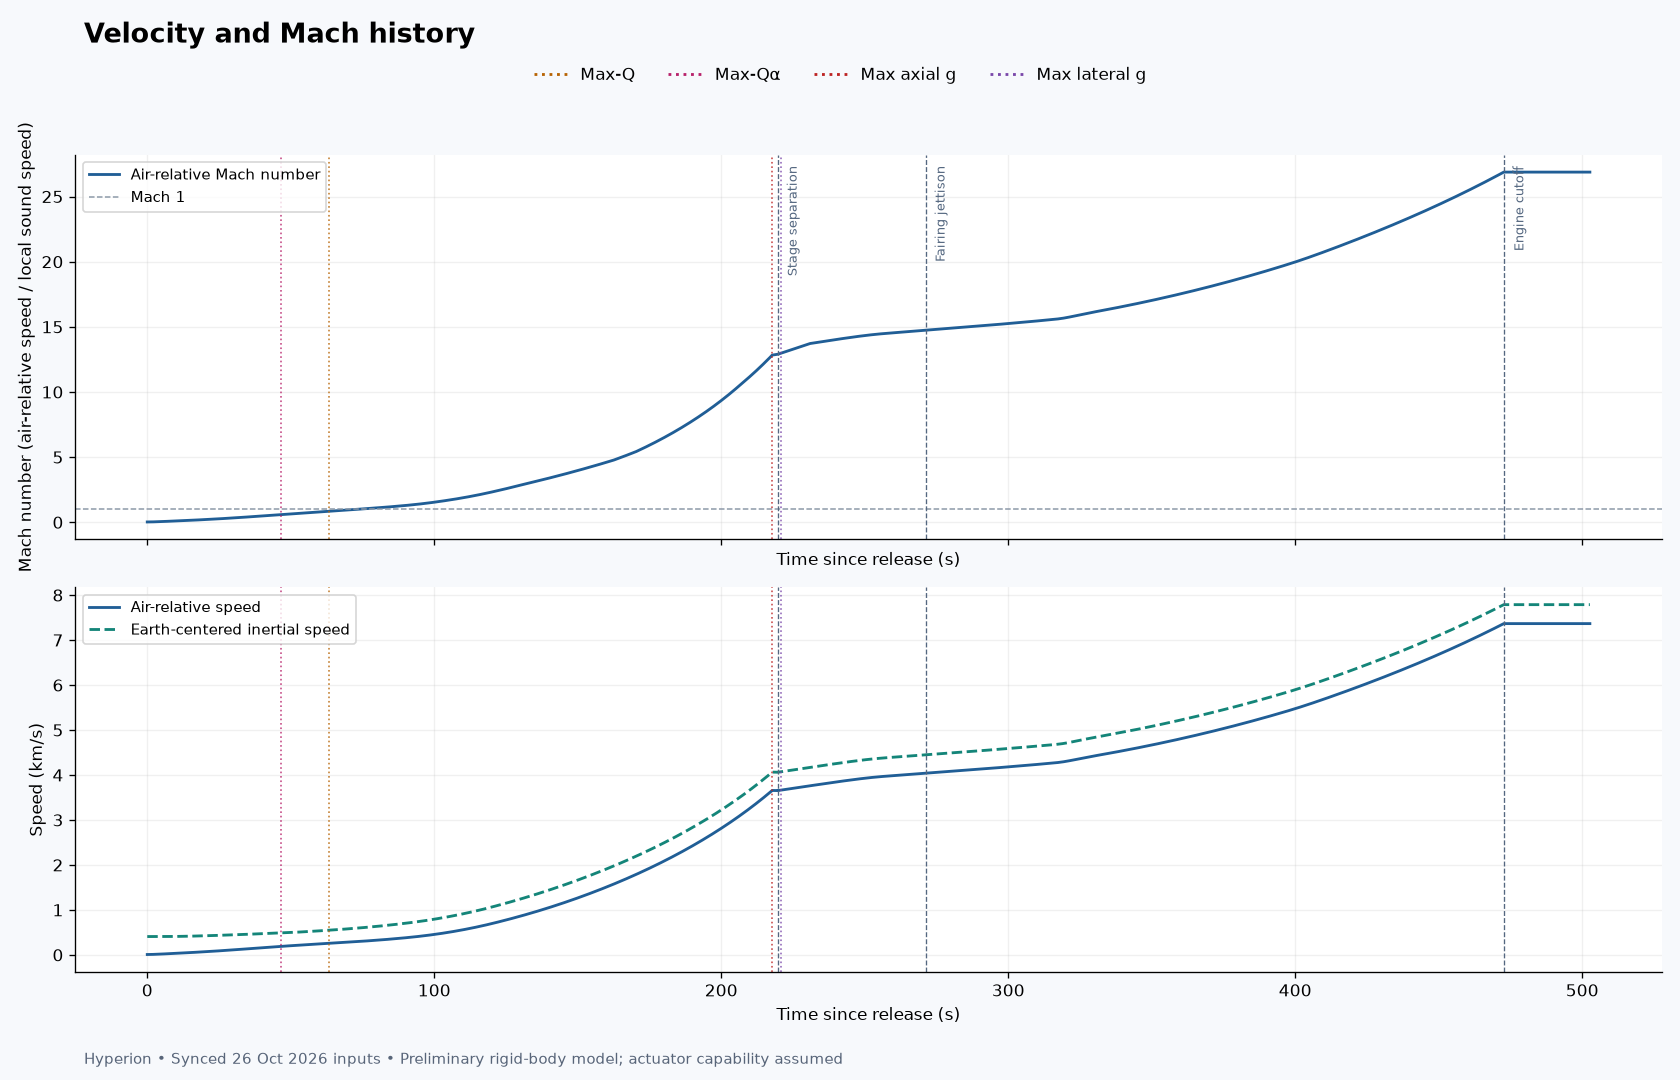

In [8]:
compare_plot(trajectory)
plot_results(trajectory, summary, RUN_CONFIG)

## 5 · Verification

Five physics tests cover frames, atmosphere references, coefficient projection and mass closure.
Conservation checks treat event jumps separately. A second RK45 run uses 10× tighter relative
tolerance, half the maximum step, and **0.05 s** output spacing. Numerical agreement does not
validate uncertain aerodynamic inputs or actuator hardware.

In [9]:
# VERIFICATION IMPLEMENTATION — expand to inspect.
class PhysicsChecks(unittest.TestCase):
    @classmethod
    def setUpClass(cls):
        cls.config=copy.deepcopy(RUN_CONFIG)

    def test_body_rate_quaternion_convention(self):
        # Independent rotation-composition check catches body/world convention swaps.
        q=Rotation.from_euler('xyz',[.3,-.4,.7]).as_quat()
        w=np.array([.2,-.3,.4]);dt=1e-6
        advanced=matrix(q+quaternion_derivative(q,w)*dt)
        reference=(Rotation.from_quat(q)*Rotation.from_rotvec(w*dt)).as_matrix()
        np.testing.assert_allclose(advanced,reference,atol=2e-13,rtol=0)

    def test_initial_frame_and_earth_corotation(self):
        sim=Simulation(self.config);y=sim.initial();q=y[6:10]
        np.testing.assert_allclose(matrix(q).T@matrix(q),np.eye(3),atol=1e-14)
        self.assertAlmostEqual(np.linalg.det(matrix(q)),1.,places=13)
        np.testing.assert_allclose(matrix(q)[:,0],y[:3]/np.linalg.norm(y[:3]),atol=1e-14)
        # Body angular-rate vector must map to inertial Earth's spin.
        np.testing.assert_allclose(matrix(q)@y[10:13],[0,0,7.292115e-5],atol=1e-16)

    def test_standard_atmosphere_reference_points(self):
        atm=Atmosphere(dict(self.config['atmosphere'],temperature_offset_K=0,density_scale=1))
        T,p,rho,a,vis=atm.sample(0)
        self.assertAlmostEqual(T,288.15,places=9)
        self.assertAlmostEqual(p,101325,places=6)
        self.assertAlmostEqual(rho,1.225,places=5)
        # 11 km geopotential is 11019.0678 m geometric in this reference model.
        z=6356766*11000/(6356766-11000)
        T,p,*_=atm.sample(z)
        self.assertAlmostEqual(T,216.65,places=8)
        self.assertAlmostEqual(p,22632.04,delta=.1)
        pressures=[atm.sample(h)[1] for h in [0,11000,20000,47000,86000,150000]]
        self.assertTrue(all(a>b>0 for a,b in zip(pressures,pressures[1:])))

    def test_aero_force_projection_and_domain(self):
        table=AeroTable(AERO_DATA,self.config['aero'])
        source=AERO_DATA
        for mach,alpha in [(.5,2.),(1.,4.),(2.,2.),(10.,4.)]:
            row=source[(source['mach']==mach)&(source['alpha_deg']==alpha)][0]
            ca,cn,cp,off=table.sample(mach,math.radians(alpha),True)
            a=math.radians(alpha)
            self.assertFalse(off)
            self.assertAlmostEqual(ca*math.cos(a)+cn*math.sin(a),row['cd_on'],places=13)
            self.assertAlmostEqual(cn*math.cos(a)-ca*math.sin(a),row['cl'],places=13)
            self.assertAlmostEqual(cp,row['cp_raw_in']*.0254,places=12)
        self.assertFalse(table.sample(24.99,math.radians(4),True)[-1])
        self.assertTrue(table.sample(25.,math.radians(4),True)[-1])
        self.assertTrue(table.sample(.001,0.,True)[-1])
        self.assertTrue(table.sample(1.,math.radians(4.01),True)[-1])

    def test_mass_closure_and_mass_shedding(self):
        c=self.config['vehicle'];v=Vehicle(c)
        p=np.array([s['propellant_kg'] for s in c['stages']])
        mass,cg,I=v.properties(p,True,True)
        expected=sum(s['dry_mass_kg']+s['propellant_kg'] for s in c['stages'])+c['payload_kg']+c['fairing_kg']
        self.assertAlmostEqual(mass,expected,places=7)
        self.assertTrue(0<cg<sum(s['length_m'] for s in c['stages']))
        self.assertTrue(np.all(I>0))
        after=v.properties(p,False,True)
        self.assertAlmostEqual(mass-after[0],c['stages'][0]['dry_mass_kg']+p[0],places=7)
        bare=v.properties(p,False,False)
        self.assertAlmostEqual(after[0]-bare[0],c['fairing_kg'],places=7)
        p[0]-=1000
        self.assertAlmostEqual(mass-v.properties(p,True,True)[0],1000,places=7)

NUMERICAL_TOLERANCES = {
    'quaternion_norm_error': 1e-6,
    'speed_balance_error_m_s': 0.02,
    'rocket_equation_error_m_s': 0.02,
    'continuous_mass_error_kg': 0.01,
    'event_velocity_jump_error_m_s': 0.001,
    'event_position_jump_error_m': 0.001,
    'loss_integral_jump_m_s': 1e-6,
}

CONVERGENCE_TOLERANCES = {
    'q_Pa': {'absolute': 100.0, 'relative': 0.005},
    'qalpha_Pa_deg': {'absolute': 100.0, 'relative': 0.01},
    'axial_g': {'absolute': 0.01, 'relative': 0.0},
    'lateral_g': {'absolute': 0.01, 'relative': 0.0},
    'cutoff_altitude_m': {'absolute': 100.0, 'relative': 0.0},
    'cutoff_inertial_speed_m_s': {'absolute': 0.1, 'relative': 0.0},
    'cutoff_vertical_speed_m_s': {'absolute': 0.1, 'relative': 0.0},
    'cutoff_t_s': {'absolute': 0.1, 'relative': 0.0},
    'event_time_s': {'absolute': 0.1, 'relative': 0.0},
}

LOSS_COLUMNS = ['ideal_dv_m_s', 'steering_loss_m_s', 'gimbal_loss_m_s',
                'drag_loss_m_s', 'gravity_loss_m_s']

PEAK_COLUMNS = ['q_Pa', 'qalpha_Pa_deg', 'axial_g', 'lateral_g']

REQUIRED_COLUMNS = [
    't_s', 'phase', 'mass_kg', 'prop1_kg', 'prop2_kg', 'cg_from_base_m',
    'altitude_m', 'inertial_speed_m_s', 'vertical_speed_m_s', 'quaternion_norm',
    'thrust_N', 'available_moment_Nm', 'required_moment_Nm', 'aero_moment_Nm',
    'aero_out_of_domain', 'aero_configuration_proxy', 'gimbal_total_deg',
    'gimbal_rate_deg_s', *LOSS_COLUMNS, *PEAK_COLUMNS,
    *[f'eci_{axis}_m' for axis in 'xyz'],
    *[f'eci_v{axis}_m_s' for axis in 'xyz'],
    *[f'body_rate_{axis}_deg_s' for axis in 'xyz'],
    *[f'quaternion_{axis}' for axis in 'xyzw'],
]

def serializable(value):
    """Emit strict JSON; nonfinite diagnostic numbers become null."""
    if isinstance(value, dict):
        return {str(k): serializable(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [serializable(v) for v in value]
    if isinstance(value, np.generic):
        return serializable(value.item())
    if isinstance(value, float) and not np.isfinite(value):
        return None
    return value

def cutoff_state(df, events):
    names = ['orbital_speed_cutoff', 'stage2_propellant_limit', 'ground_contact',
             'time_limit', 'terminated_before_stage1_burnout']
    chosen = next((event for name in names for event in events if event['event'] == name), None)
    if chosen is None:
        row = df.iloc[-1]
        reason = 'last_recorded_sample'
    else:
        distance = np.abs(df.t_s.to_numpy() - chosen['t_s'])
        candidates = np.flatnonzero(distance <= distance.min() + 1e-9)
        # Both sides of cutoff are recorded; prefer the final powered state.
        powered = [i for i in candidates if df.thrust_N.iloc[i] > 0]
        row = df.iloc[powered[0] if powered else candidates[0]]
        reason = chosen['event']
    return dict(event=reason, **{key: float(row[key]) for key in [
        't_s', 'altitude_m', 'inertial_speed_m_s', 'vertical_speed_m_s']})

def audit_rows(df, events, config):
    """Check continuous segments independently, excluding recorded event jumps."""
    missing = sorted(set(REQUIRED_COLUMNS) - set(df.columns))
    if missing or df.empty:
        return {'numerical_pass': False, 'missing_columns': missing, 'empty_trajectory': bool(df.empty)}
    df = df.reset_index(drop=True)
    finite = bool(np.isfinite(df[REQUIRED_COLUMNS].to_numpy(dtype=float)).all())
    if not finite:
        return {'numerical_pass': False, 'checks': {'finite_required_values': False},
                'nonfinite_columns': [k for k in REQUIRED_COLUMNS if not np.isfinite(df[k]).all()]}

    times = df.t_s.to_numpy()
    dt = np.diff(times)
    phases = df.phase.to_numpy(dtype=int)
    # Each solve records its endpoint and the next solve's start. Preserve both
    # sides; never apply a continuous rocket equation across a separation jump.
    cuts = np.r_[0, np.flatnonzero((dt <= 1e-8) | (np.diff(phases) != 0)) + 1, len(df)]
    segments = []
    for start, stop in zip(cuts[:-1], cuts[1:]):
        part = df.iloc[start:stop]
        if len(part) < 2:
            continue
        first, last = part.iloc[0], part.iloc[-1]
        speed_change = part.inertial_speed_m_s - first.inertial_speed_m_s
        budget = ((part.ideal_dv_m_s - first.ideal_dv_m_s)
                  - (part.steering_loss_m_s - first.steering_loss_m_s)
                  - (part.drag_loss_m_s - first.drag_loss_m_s)
                  - (part.gravity_loss_m_s - first.gravity_loss_m_s))
        phase = int(first.phase)
        if phase in (1, 2):
            isp = config['vehicle']['stages'][phase - 1]['isp_s']
            rocket = isp * G0 * np.log(first.mass_kg / part.mass_kg)
        else:
            rocket = np.zeros(len(part))
        rocket_error = (part.ideal_dv_m_s - first.ideal_dv_m_s) - rocket
        mass_error = ((part.mass_kg - first.mass_kg)
                      - (part.prop1_kg - first.prop1_kg)
                      - (part.prop2_kg - first.prop2_kg))
        segments.append({
            'phase': phase, 'start_row': int(start), 'end_row': int(stop - 1),
            'start_t_s': float(first.t_s), 'end_t_s': float(last.t_s), 'sample_count': len(part),
            'speed_change_m_s': float(speed_change.iloc[-1]),
            'projected_delta_v_budget_m_s': float(budget.iloc[-1]),
            'speed_balance_endpoint_error_m_s': float((speed_change - budget).iloc[-1]),
            'max_speed_balance_error_m_s': float(np.max(np.abs(speed_change - budget))),
            'max_rocket_equation_error_m_s': float(np.max(np.abs(rocket_error))),
            'max_continuous_mass_error_kg': float(np.max(np.abs(mass_error))),
        })

    jumps = []
    for i in np.flatnonzero(np.abs(dt) <= 1e-8):
        before, after = df.iloc[i], df.iloc[i + 1]
        q = np.array([before[f'quaternion_{axis}'] for axis in 'xyzw'])
        Q = matrix(q)
        w = np.deg2rad([before[f'body_rate_{axis}_deg_s'] for axis in 'xyz'])
        shift_body = np.array([after.cg_from_base_m - before.cg_from_base_m, 0.0, 0.0])
        at_time = [ev for ev in events if abs(ev['t_s'] - before.t_s) < 1e-6]
        separation = next((ev for ev in at_time if ev['event'] == 'stage_separation'), None)
        dv = separation['upper_delta_v_m_s'] if separation and before.phase != after.phase else 0.0
        expected_velocity_jump = Q @ (np.cross(w, shift_body) + np.array([dv, 0.0, 0.0]))
        actual_velocity_jump = np.array([after[f'eci_v{axis}_m_s'] - before[f'eci_v{axis}_m_s'] for axis in 'xyz'])
        actual_position_jump = np.array([after[f'eci_{axis}_m'] - before[f'eci_{axis}_m'] for axis in 'xyz'])
        jumps.append({
            't_s': float(before.t_s), 'before_phase': int(before.phase), 'after_phase': int(after.phase),
            'events': [ev['event'] for ev in at_time], 'mass_jump_kg': float(after.mass_kg - before.mass_kg),
            'cg_jump_m': float(shift_body[0]),
            'velocity_jump_error_m_s': float(np.linalg.norm(actual_velocity_jump - expected_velocity_jump)),
            'position_jump_error_m': float(np.linalg.norm(actual_position_jump - Q @ shift_body)),
            'max_loss_integral_jump_m_s': float(max(abs(after[key] - before[key]) for key in LOSS_COLUMNS)),
        })

    def maximum(records, key):
        return max((item[key] for item in records), default=0.0)

    errors = {
        'quaternion_norm_error': float(np.max(np.abs(df.quaternion_norm - 1.0))),
        'speed_balance_error_m_s': maximum(segments, 'max_speed_balance_error_m_s'),
        'rocket_equation_error_m_s': maximum(segments, 'max_rocket_equation_error_m_s'),
        'continuous_mass_error_kg': maximum(segments, 'max_continuous_mass_error_kg'),
        'event_velocity_jump_error_m_s': maximum(jumps, 'velocity_jump_error_m_s'),
        'event_position_jump_error_m': maximum(jumps, 'position_jump_error_m'),
        'loss_integral_jump_m_s': maximum(jumps, 'max_loss_integral_jump_m_s'),
    }
    numerical = {key: bool(value <= NUMERICAL_TOLERANCES[key]) for key, value in errors.items()}
    numerical.update(finite_required_values=finite, nondecreasing_time=bool((dt >= -1e-8).all()),
                     positive_mass=bool((df.mass_kg > 0).all()),
                     nonnegative_propellant=bool((df[['prop1_kg', 'prop2_kg']] >= -0.01).all().all()),
                     continuous_segments_present=bool(segments))
    powered = df.thrust_N > 0
    loaded = df.q_Pa > 100.0
    ratio_margin = df.available_moment_Nm - config['limits']['control_ratio'] * df.aero_moment_Nm
    sample_checks = {
        'axial_acceleration_pass': bool((df.axial_g.abs() <= config['limits']['axial_g']).all()),
        'lateral_acceleration_pass': bool((df.lateral_g <= config['limits']['lateral_g']).all()),
        'aero_table_domain_all_samples_pass': bool((df.aero_out_of_domain == 0).all()),
        'aero_table_domain_above_100Pa_pass': bool((df.loc[loaded, 'aero_out_of_domain'] == 0).all()),
        'control_at_least_aero_all_samples_pass': bool((df.available_moment_Nm - df.aero_moment_Nm >= -1e-8).all()),
        'control_ratio_all_samples_pass': bool((ratio_margin >= -1e-8).all()),
        'control_ratio_powered_samples_pass': bool((ratio_margin[powered] >= -1e-8).all()),
        'tracking_demand_within_powered_capacity_pass': bool((df.loc[powered, 'required_moment_Nm'] <= df.loc[powered, 'available_moment_Nm'] + 1e-6).all()),
    }
    peaks = {}
    for key in PEAK_COLUMNS:
        row = df.iloc[int(np.argmax(np.abs(df[key].to_numpy())))]
        peaks[key] = {'value': float(row[key]), 'magnitude': abs(float(row[key])), 't_s': float(row.t_s)}
    return {
        'numerical_pass': all(numerical.values()), 'numerical_checks': numerical,
        'numerical_error_maxima': errors, 'continuous_segments': segments, 'event_jumps': jumps,
        'sample_count': len(df), 'duration_s': float(times[-1] - times[0]),
        'sampled_design_checks': sample_checks, 'peaks': peaks, 'cutoff_state': cutoff_state(df, events),
        'outside_table_samples': int(df.aero_out_of_domain.sum()),
        'outside_table_above_100Pa_samples': int(df.loc[loaded, 'aero_out_of_domain'].sum()),
        'configuration_proxy_samples': int(df.aero_configuration_proxy.sum()),
        'worst_control_ratio_margin_Nm': float(ratio_margin.min()), 'events': events,
    }

def compare_value(nominal, refined, tolerances):
    difference = abs(refined - nominal)
    scale = max(abs(nominal), abs(refined))
    allowed = tolerances['absolute'] + tolerances['relative'] * scale
    return {'nominal': nominal, 'refined': refined, 'absolute_difference': difference,
            'relative_difference': difference / scale if scale else 0.0,
            'allowed_difference': allowed, 'pass': difference <= allowed}

def compare_runs(nominal, refined):
    values = {}
    for key in PEAK_COLUMNS:
        values[key] = compare_value(nominal['peaks'][key]['magnitude'], refined['peaks'][key]['magnitude'], CONVERGENCE_TOLERANCES[key])
        values[key]['nominal_peak_t_s'] = nominal['peaks'][key]['t_s']
        values[key]['refined_peak_t_s'] = refined['peaks'][key]['t_s']
        # A flat maximum can move in time without a meaningful value change.
        values[key]['peak_time_difference_s'] = abs(nominal['peaks'][key]['t_s'] - refined['peaks'][key]['t_s'])
    for key in ['altitude_m', 'inertial_speed_m_s', 'vertical_speed_m_s', 't_s']:
        name = 'cutoff_' + key
        values[name] = compare_value(nominal['cutoff_state'][key], refined['cutoff_state'][key], CONVERGENCE_TOLERANCES[name])
    events_a, events_b = nominal['events'], refined['events']
    same_sequence = [ev['event'] for ev in events_a] == [ev['event'] for ev in events_b]
    event_differences = []
    if same_sequence:
        for a, b in zip(events_a, events_b):
            comparison = compare_value(float(a['t_s']), float(b['t_s']), CONVERGENCE_TOLERANCES['event_time_s'])
            event_differences.append({'event': a['event'], **comparison})
    same_cutoff = nominal['cutoff_state']['event'] == refined['cutoff_state']['event']
    return {'pass': bool(same_sequence and same_cutoff and all(v['pass'] for v in values.values())
                         and all(v['pass'] for v in event_differences)),
            'same_event_sequence': same_sequence, 'same_cutoff_reason': same_cutoff,
            'metrics': values, 'event_time_comparison': event_differences,
            'sampled_design_checks_agree': nominal['sampled_design_checks'] == refined['sampled_design_checks']}

In [10]:
test_log = io.StringIO()
unit_result = unittest.TextTestRunner(stream=test_log).run(unittest.defaultTestLoader.loadTestsFromTestCase(PhysicsChecks))
assert unit_result.wasSuccessful(), test_log.getvalue()
nominal_audit = audit_rows(trajectory, events, RUN_CONFIG)
assert nominal_audit['numerical_pass'], 'Numerical conservation check failed.'
print(f'{unit_result.testsRun} physics tests: PASS. Conservation checks: PASS.')
convergence = None
if RUN_REFINEMENT:
    refined_config = copy.deepcopy(RUN_CONFIG)
    refined_config['solver']['rtol'] /= 10
    refined_config['solver']['max_step_s'] /= 2
    refined_config['solver']['output_step_s'] = min(.05,RUN_CONFIG['solver']['output_step_s'])
    refined_rows, refined_events = Simulation(refined_config).run()
    refined_df = pd.DataFrame(refined_rows)
    refined_audit = audit_rows(refined_df, refined_events, refined_config)
    convergence = compare_runs(nominal_audit, refined_audit)
    assert refined_audit['numerical_pass'] and convergence['pass'], 'Review refinement differences.'
    rp = refined_df.loc[refined_df.qalpha_Pa_deg.idxmax()]
    print(f'RK45 refinement: PASS. Max-Qα={rp.qalpha_Pa_deg/1000:.4f} kPa·deg; AoA={rp.alpha_deg:.4f}°.')
    print('Refined requested criterion:', 'PASS' if rp.alpha_deg < 4 and rp.qalpha_Pa_deg < old['qalpha_Pa_deg'] else 'FAIL')
else:
    print('Refinement skipped; no new convergence claim.')

5 physics tests: PASS. Conservation checks: PASS.


RK45 refinement: PASS. Max-Qα=31.8058 kPa·deg; AoA=2.1825°.
Refined requested criterion: PASS


## 6 · Interpretation and sources

- **Below 4° at max-Qα does not mean below 4° throughout flight.** Early wind incidence still
  exceeds the lookup range. Aerodynamics after staging/fairing release remain a flagged proxy.
- **Coast control still fails:** TVC is zero when engines are off and no RCS torque is allocated.
  The 5° gimbal/5°·s⁻¹ slew capability and detailed mass distribution are assumptions.
- CP is tentatively **inches from the nose**. Original export geometry/area are unverified.
  Peak loads exclude shock, flexibility, slosh, and stage recontact.
- This is a parking-orbit run, not TMI. Remaining ideal Δv does not establish mission closure.

References: [U.S. Standard Atmosphere 1976](https://www.ngdc.noaa.gov/stp/space-weather/online-publications/miscellaneous/us-standard-atmosphere-1976/us-standard-atmosphere_st76-1562_noaa.pdf)
and [RASAero II manual](https://www.rasaero.com/dloads/RASAero%20II%20Users%20Manual.pdf).
Source workbook names, selected values and full hashes are embedded in notebook metadata.

In [11]:
source_table = pd.DataFrame(snapshot['source_audit']['source_provenance']).T[['sha256']]
source_table['sha256'] = source_table.sha256.str[:16] + '…'
display(HTML('<details><summary>Show source snapshot fingerprints</summary>'+source_table.to_html()+'</details>'))

# Optional numeric exports; leaves the shared drive untouched.
EXPORT_RESULTS = False
if EXPORT_RESULTS:
    out = Path('hyperion_exports'); out.mkdir(exist_ok=True)
    trajectory.to_csv(out/'trajectory.csv',index=False)
    load_cases.to_csv(out/'load_cases.csv',index=False)
    (out/'config_used.json').write_text(json.dumps(RUN_CONFIG,indent=2),encoding='utf-8')
    print('Saved:',out.resolve())

,sha256
AE 443 Team A PDR.pptx,e534c45d624d3447…
AE 443 Team A Requirements - Submission Ready.xlsx,d1934a48b791170b…
Hyperion Master Sheet snapshot.xlsx,393d7e15f229e7ca…
Hyperion Master Sheet synced.xlsx,5d4df6ed249a9429…
Meeting Notes.docx,7265335966e4560f…
Mlox-Hlox.xlsx,e017eaf89138d537…
Structures Sizing.xlsx,f31b2d13aa906850…
